In [11]:
# ==========================================
# DATA CLEANING & PREPROCESSING
# ==========================================

import pandas as pd
import numpy as np

# 1. Load Dataset
# Locate the dataset automatically (Kaggle, Google Colab, or local VS Code/Jupyter).
from pathlib import Path

dataset_filename = "E-Commerce Sales Analytics.csv"
possible_paths = [
    Path("/kaggle/input/datasets/srisyra02/e-commerce-sales-performance-analysis") / dataset_filename,
    Path("/kaggle/input/e-commerce-sales-performance-analysis") / dataset_filename,
    Path("/content") / dataset_filename,
    Path.cwd() / dataset_filename,
]

dataset_path = next((path for path in possible_paths if path.is_file()), None)

# If the CSV is inside a folder in the current working directory, search for it.
if dataset_path is None:
    matches = list(Path.cwd().rglob(dataset_filename))
    if matches:
        dataset_path = matches[0]

if dataset_path is None:
    raise FileNotFoundError(
        f"Could not find '{dataset_filename}'. Put the CSV in the same folder "
        "as this notebook, or upload/mount the dataset before running the cells."
    )

print(f"Dataset found: {dataset_path}")

df = pd.read_csv(dataset_path)

print("--- 📌 1. FIRST 5 ROWS (df.head()) ---")
print(df.head())

print("\n--- 📌 2. DATASET SUMMARY & TYPES (df.info()) ---")
print(df.info())

print("\n--- 📌 3. DESCRIPTIVE STATISTICS (df.describe()) ---")
print(df.describe().T)

print("\n--- 📌 4. MISSING VALUES COUNT (df.isnull().sum()) ---")
print(df.isnull().sum())

# 2. Data Preprocessing & Cleaning
# Convert order_date to datetime format
df['order_date'] = pd.to_datetime(df['order_date'])

# Strip leading/trailing whitespaces for string/object columns
str_cols = df.select_dtypes(include=['object']).columns
for col in str_cols:
    df[col] = df[col].str.strip()

# Check for duplicated records
duplicates_count = df.duplicated().sum()
print(f"\n--- 📌 5. DUPLICATE RECORDS REMOVED: {duplicates_count} ---")
df = df.drop_duplicates()

# Sort chronologically by order_date
df = df.sort_values('order_date').reset_index(drop=True)

print("\n✅ Data Preprocessing Complete! Clean dataset shape:", df.shape)

Dataset found: c:\Users\MICHAEL LAWRENCE\E-commerce_Dataset_web_Acapulco_Manansala_Cruz\Data\E-Commerce Sales Analytics.csv
--- 📌 1. FIRST 5 ROWS (df.head()) ---
   order_id order_date  customer_id product_category region  quantity  \
0     10001   1/1/2022         1102           Beauty  South         7   
1     10002   1/2/2022         1435         Clothing  South         7   
2     10003   1/3/2022         1860           Beauty   East         3   
3     10004   1/4/2022         1270      Electronics   West         5   
4     10005   1/5/2022         1106         Clothing   West         5   

   unit_price  discount payment_method  delivery_days  customer_rating  \
0      373.65      0.28         Wallet             10              4.7   
1       47.74      0.09           Card              6              3.9   
2      311.28      0.31            COD              6              2.5   
3      524.47      0.02         Wallet              6              1.6   
4      139.87      0.33      

C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\3120618830.py:55: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  str_cols = df.select_dtypes(include=['object']).columns


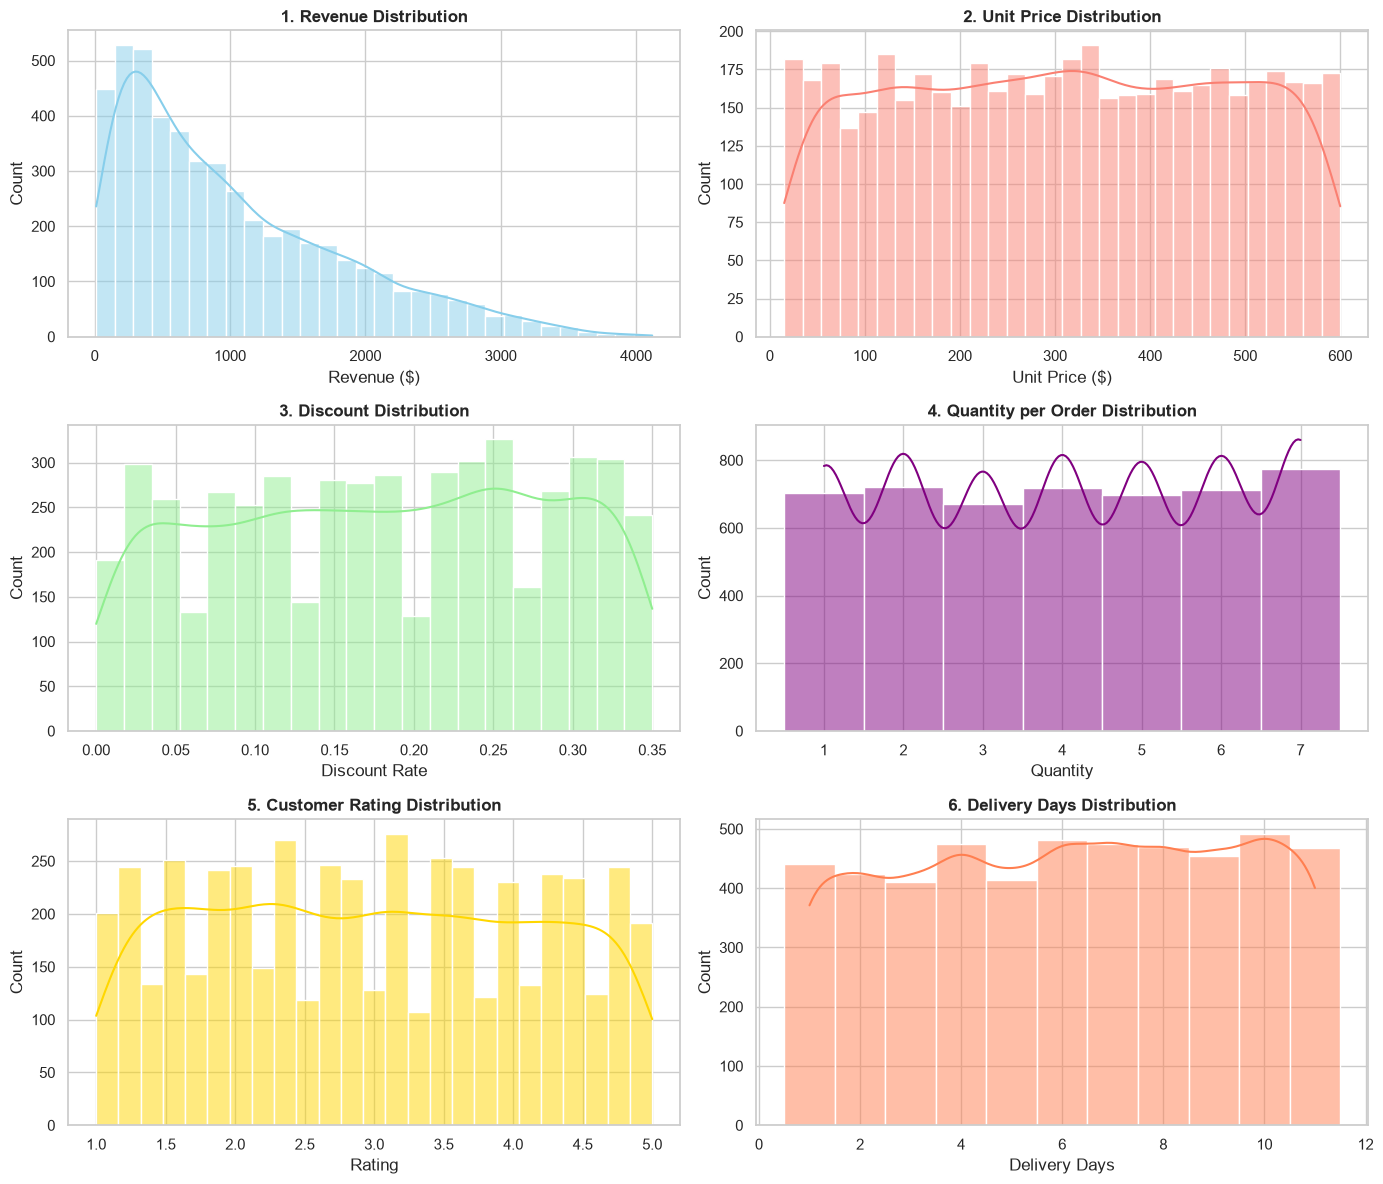

In [12]:
# ==========================================
# HISTOGRAMS 
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

# 1. Revenue Distribution
sns.histplot(data=df, x='revenue', kde=True, ax=axes[0,0], color='skyblue', bins=30)
axes[0,0].set_title('1. Revenue Distribution', fontsize=12, fontweight='bold')
axes[0,0].set_xlabel('Revenue ($)')

# 2. Unit Price Distribution
sns.histplot(data=df, x='unit_price', kde=True, ax=axes[0,1], color='salmon', bins=30)
axes[0,1].set_title('2. Unit Price Distribution', fontsize=12, fontweight='bold')
axes[0,1].set_xlabel('Unit Price ($)')

# 3. Discount Distribution
sns.histplot(data=df, x='discount', kde=True, ax=axes[1,0], color='lightgreen', bins=20)
axes[1,0].set_title('3. Discount Distribution', fontsize=12, fontweight='bold')
axes[1,0].set_xlabel('Discount Rate')

# 4. Quantity Distribution
sns.histplot(data=df, x='quantity', kde=True, ax=axes[1,1], color='purple', bins=7, discrete=True)
axes[1,1].set_title('4. Quantity per Order Distribution', fontsize=12, fontweight='bold')
axes[1,1].set_xlabel('Quantity')

# 5. Customer Rating Distribution
sns.histplot(data=df, x='customer_rating', kde=True, ax=axes[2,0], color='gold', bins=25)
axes[2,0].set_title('5. Customer Rating Distribution', fontsize=12, fontweight='bold')
axes[2,0].set_xlabel('Rating')

# 6. Delivery Days Distribution
sns.histplot(data=df, x='delivery_days', kde=True, ax=axes[2,1], color='coral', bins=11, discrete=True)
axes[2,1].set_title('6. Delivery Days Distribution', fontsize=12, fontweight='bold')
axes[2,1].set_xlabel('Delivery Days')

plt.tight_layout()
plt.show()

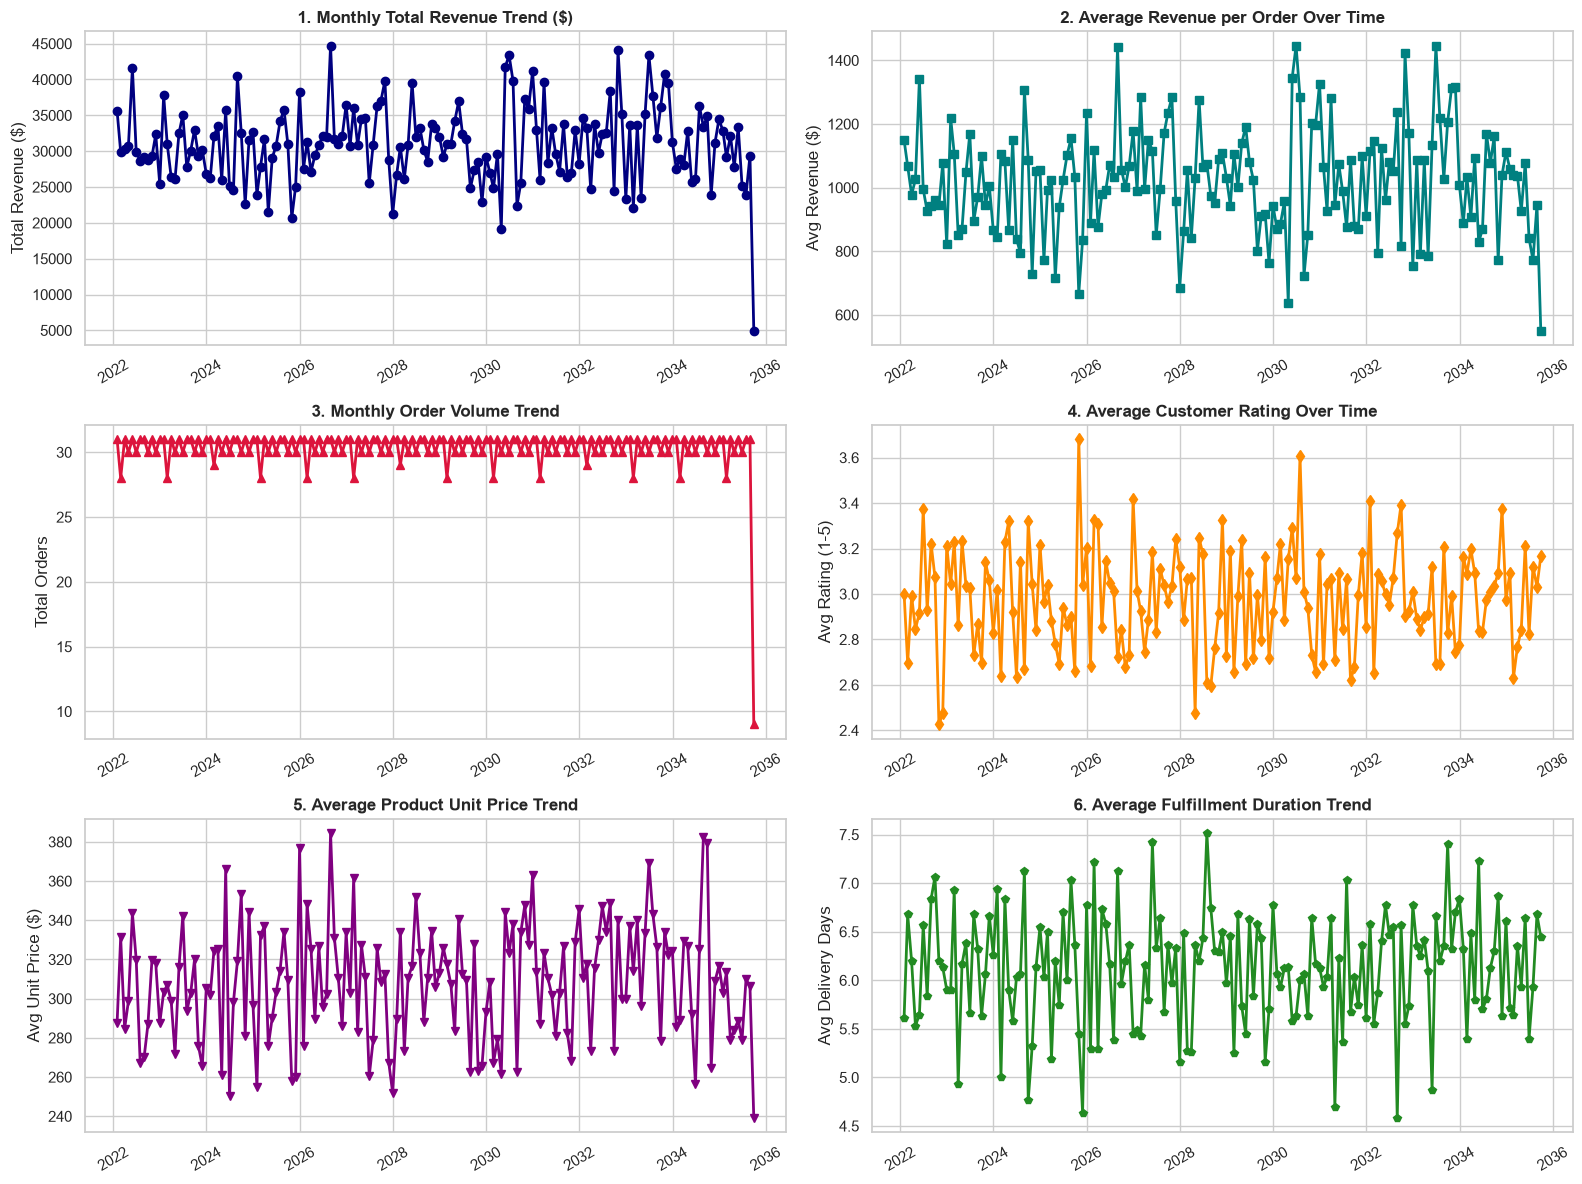

In [13]:
# ==========================================
# LINEPLOTS
# ==========================================

# Resample time series metrics on a monthly basis
df_monthly = df.set_index('order_date').resample('ME').agg({
    'revenue': ['sum', 'mean'],
    'order_id': 'count',
    'customer_rating': 'mean',
    'unit_price': 'mean',
    'delivery_days': 'mean'
}).reset_index()

df_monthly.columns = ['order_date', 'total_revenue', 'avg_revenue', 'order_count', 'avg_rating', 'avg_unit_price', 'avg_delivery_days']

fig, axes = plt.subplots(3, 2, figsize=(16, 12))

# Plot 1: Total Monthly Revenue Trend
axes[0,0].plot(df_monthly['order_date'], df_monthly['total_revenue'], marker='o', color='navy', linewidth=2)
axes[0,0].set_title('1. Monthly Total Revenue Trend ($)', fontweight='bold')
axes[0,0].set_ylabel('Total Revenue ($)')

# Plot 2: Average Revenue per Order Over Time
axes[0,1].plot(df_monthly['order_date'], df_monthly['avg_revenue'], marker='s', color='teal', linewidth=2)
axes[0,1].set_title('2. Average Revenue per Order Over Time', fontweight='bold')
axes[0,1].set_ylabel('Avg Revenue ($)')

# Plot 3: Monthly Order Volume
axes[1,0].plot(df_monthly['order_date'], df_monthly['order_count'], marker='^', color='crimson', linewidth=2)
axes[1,0].set_title('3. Monthly Order Volume Trend', fontweight='bold')
axes[1,0].set_ylabel('Total Orders')

# Plot 4: Average Customer Rating Over Time
axes[1,1].plot(df_monthly['order_date'], df_monthly['avg_rating'], marker='d', color='darkorange', linewidth=2)
axes[1,1].set_title('4. Average Customer Rating Over Time', fontweight='bold')
axes[1,1].set_ylabel('Avg Rating (1-5)')

# Plot 5: Average Unit Price Trend
axes[2,0].plot(df_monthly['order_date'], df_monthly['avg_unit_price'], marker='v', color='purple', linewidth=2)
axes[2,0].set_title('5. Average Product Unit Price Trend', fontweight='bold')
axes[2,0].set_ylabel('Avg Unit Price ($)')

# Plot 6: Average Delivery Days Trend
axes[2,1].plot(df_monthly['order_date'], df_monthly['avg_delivery_days'], marker='p', color='forestgreen', linewidth=2)
axes[2,1].set_title('6. Average Fulfillment Duration Trend', fontweight='bold')
axes[2,1].set_ylabel('Avg Delivery Days')

for ax in axes.flat:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\1541130161.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='product_category', palette='Set2', ax=axes[0,0])
C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\1541130161.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='region', palette='Set3', ax=axes[0,1])
C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\1541130161.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='payment_method', palette='Pastel1', ax=axes

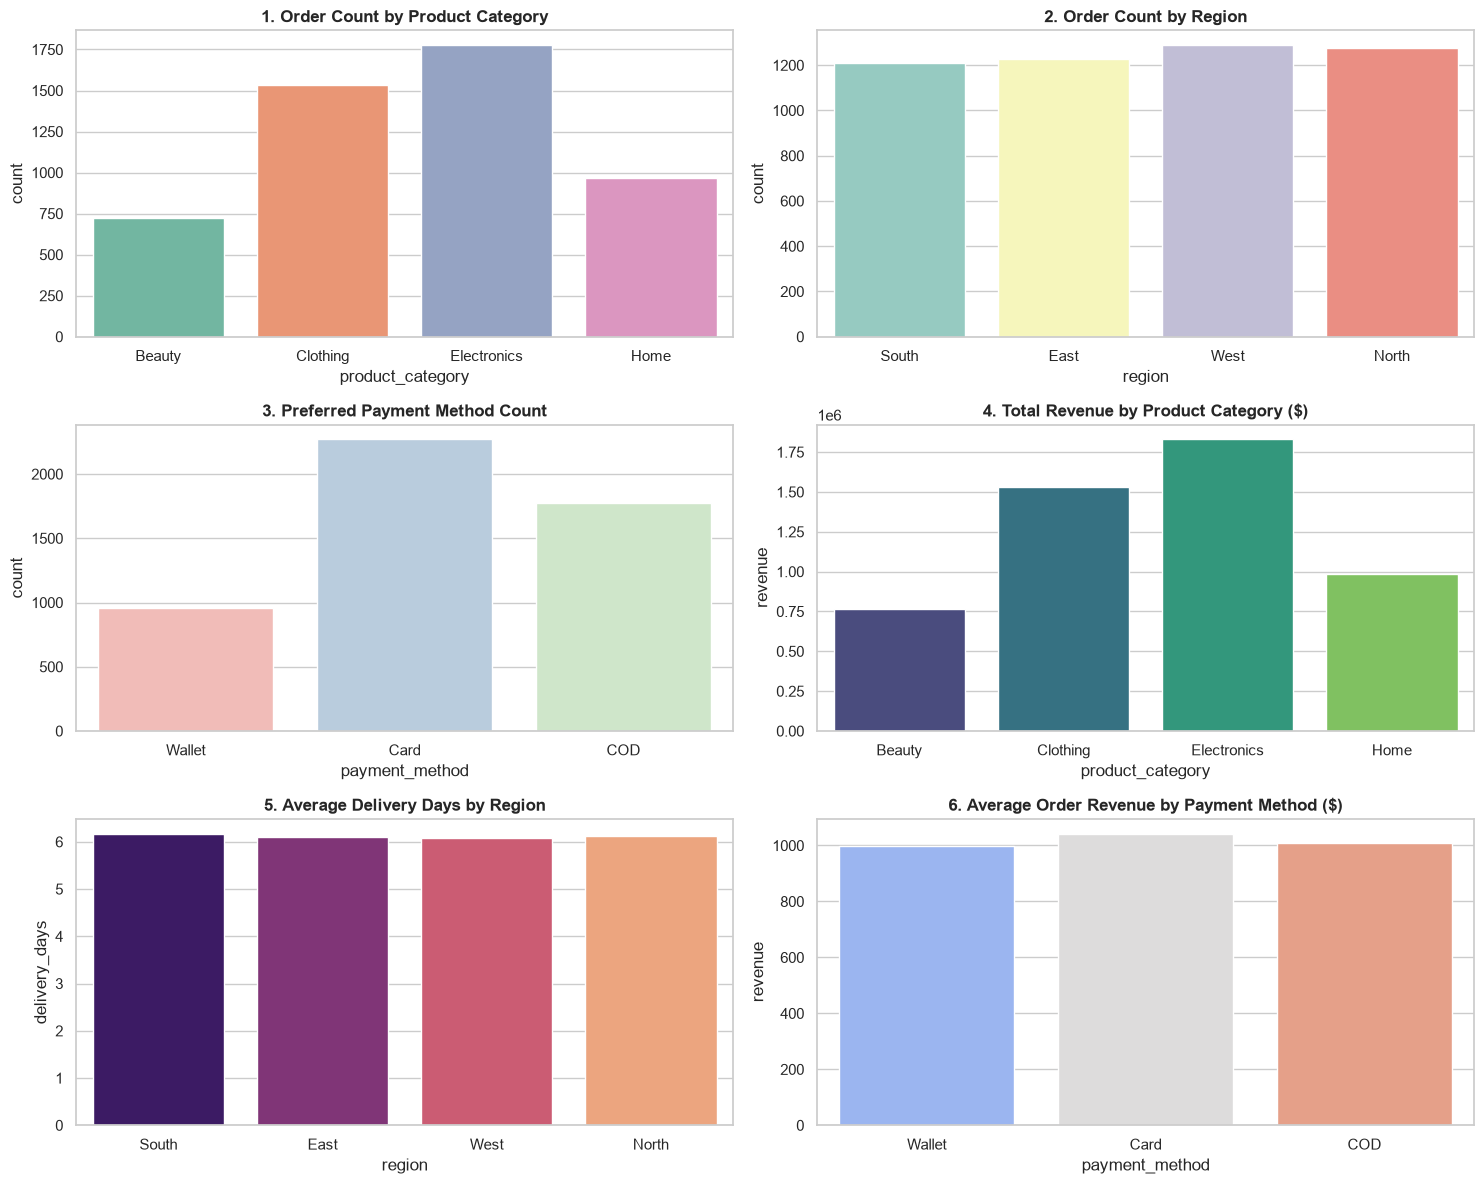

In [14]:
# ==========================================
# BARPLOTS & COUNTPLOTS
# ==========================================

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# Plot 1: Order Count by Product Category
sns.countplot(data=df, x='product_category', palette='Set2', ax=axes[0,0])
axes[0,0].set_title('1. Order Count by Product Category', fontweight='bold')

# Plot 2: Order Count by Region
sns.countplot(data=df, x='region', palette='Set3', ax=axes[0,1])
axes[0,1].set_title('2. Order Count by Region', fontweight='bold')

# Plot 3: Order Count by Payment Method
sns.countplot(data=df, x='payment_method', palette='Pastel1', ax=axes[1,0])
axes[1,0].set_title('3. Preferred Payment Method Count', fontweight='bold')

# Plot 4: Total Revenue by Product Category
sns.barplot(data=df, x='product_category', y='revenue', estimator=sum, ci=None, palette='viridis', ax=axes[1,1])
axes[1,1].set_title('4. Total Revenue by Product Category ($)', fontweight='bold')

# Plot 5: Average Delivery Days by Region
sns.barplot(data=df, x='region', y='delivery_days', estimator=np.mean, ci=None, palette='magma', ax=axes[2,0])
axes[2,0].set_title('5. Average Delivery Days by Region', fontweight='bold')

# Plot 6: Average Revenue by Payment Method
sns.barplot(data=df, x='payment_method', y='revenue', estimator=np.mean, ci=None, palette='coolwarm', ax=axes[2,1])
axes[2,1].set_title('6. Average Order Revenue by Payment Method ($)', fontweight='bold')

plt.tight_layout()
plt.show()

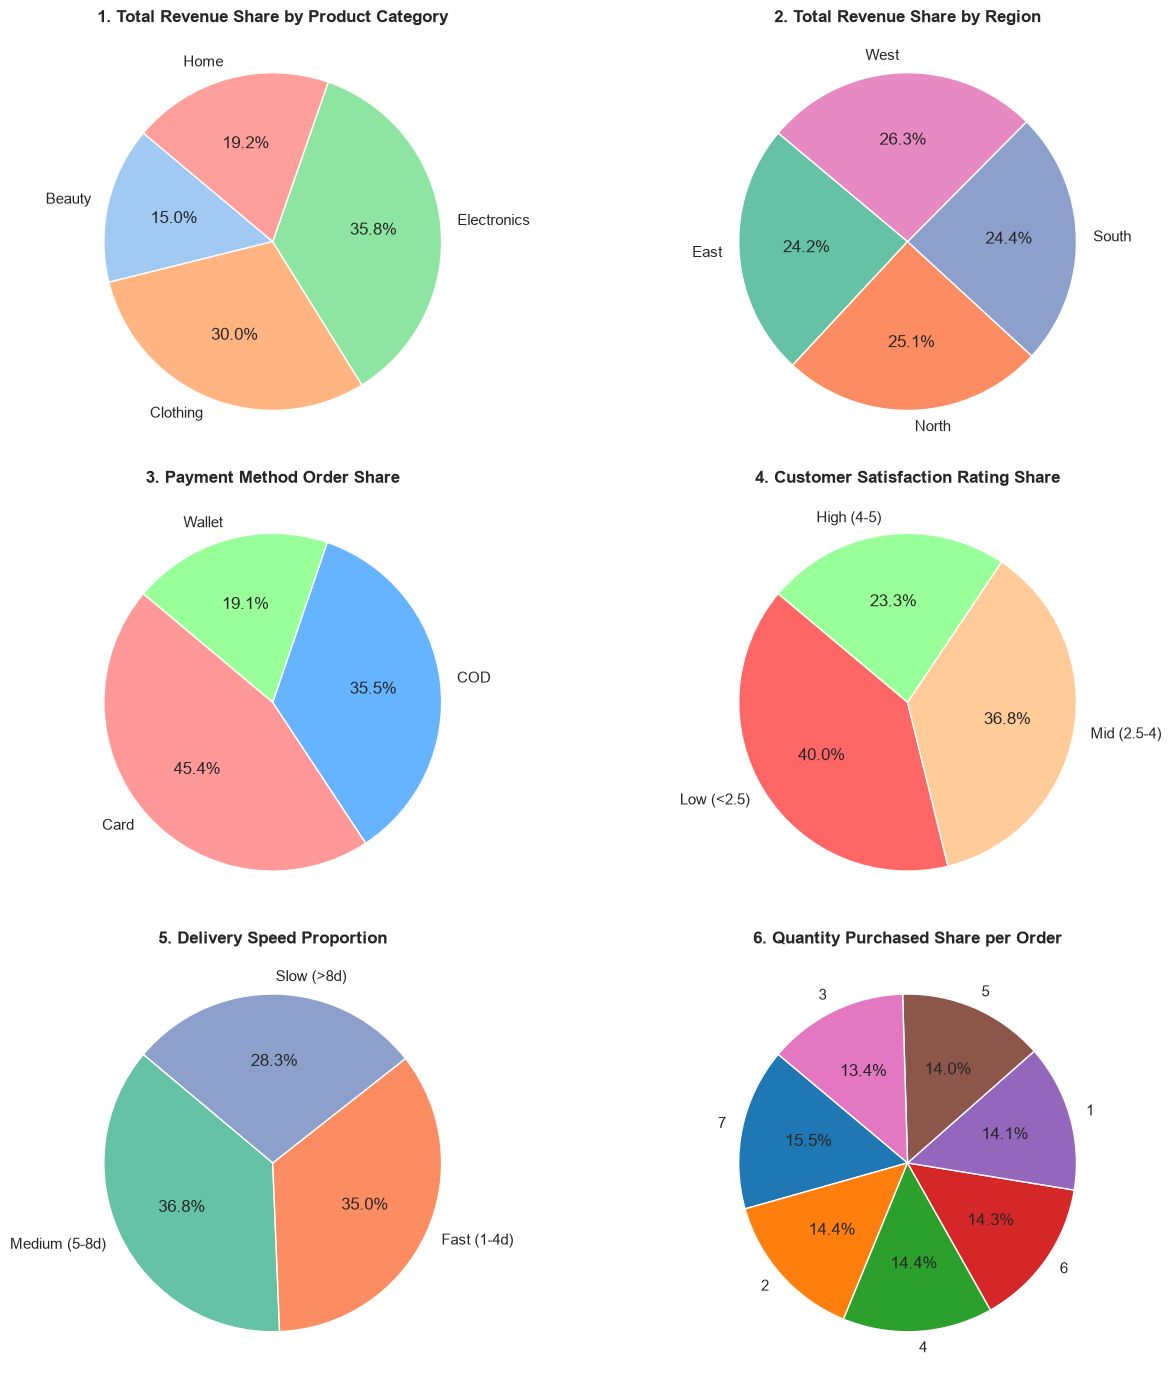

In [15]:
# ==========================================
# PIEPLOTS
# ==========================================

# Create binned helper columns for pie visualizations
df['rating_bucket'] = pd.cut(df['customer_rating'], bins=[0, 2.5, 4.0, 5.0], labels=['Low (<2.5)', 'Mid (2.5-4)', 'High (4-5)'])
df['delivery_speed'] = pd.cut(df['delivery_days'], bins=[0, 4, 8, 15], labels=['Fast (1-4d)', 'Medium (5-8d)', 'Slow (>8d)'])

fig, axes = plt.subplots(3, 2, figsize=(14, 14))

# Plot 1: Revenue Share by Product Category
cat_rev = df.groupby('product_category')['revenue'].sum()
axes[0,0].pie(cat_rev, labels=cat_rev.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
axes[0,0].set_title('1. Total Revenue Share by Product Category', fontweight='bold')

# Plot 2: Revenue Share by Region
reg_rev = df.groupby('region')['revenue'].sum()
axes[0,1].pie(reg_rev, labels=reg_rev.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('Set2'))
axes[0,1].set_title('2. Total Revenue Share by Region', fontweight='bold')

# Plot 3: Payment Method Volume Share
pay_counts = df['payment_method'].value_counts()
axes[1,0].pie(pay_counts, labels=pay_counts.index, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99'])
axes[1,0].set_title('3. Payment Method Order Share', fontweight='bold')

# Plot 4: Customer Rating Bucket Proportion
rate_counts = df['rating_bucket'].value_counts()
axes[1,1].pie(rate_counts, labels=rate_counts.index, autopct='%1.1f%%', startangle=140, colors=['#ff6666','#ffcc99','#99ff99'])
axes[1,1].set_title('4. Customer Satisfaction Rating Share', fontweight='bold')

# Plot 5: Delivery Speed Tier Share
speed_counts = df['delivery_speed'].value_counts()
axes[2,0].pie(speed_counts, labels=speed_counts.index, autopct='%1.1f%%', startangle=140, colors=['#66c2a5','#fc8d62','#8da0cb'])
axes[2,0].set_title('5. Delivery Speed Proportion', fontweight='bold')

# Plot 6: Quantity per Order Share
qty_counts = df['quantity'].value_counts()
axes[2,1].pie(qty_counts, labels=qty_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('tab10'))
axes[2,1].set_title('6. Quantity Purchased Share per Order', fontweight='bold')

plt.tight_layout()
plt.show()

C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\2756608461.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='product_category', y='revenue', palette='Set2', ax=axes[0,0])
C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\2756608461.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='product_category', y='unit_price', palette='Set3', ax=axes[0,1])
C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\2756608461.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='region', y

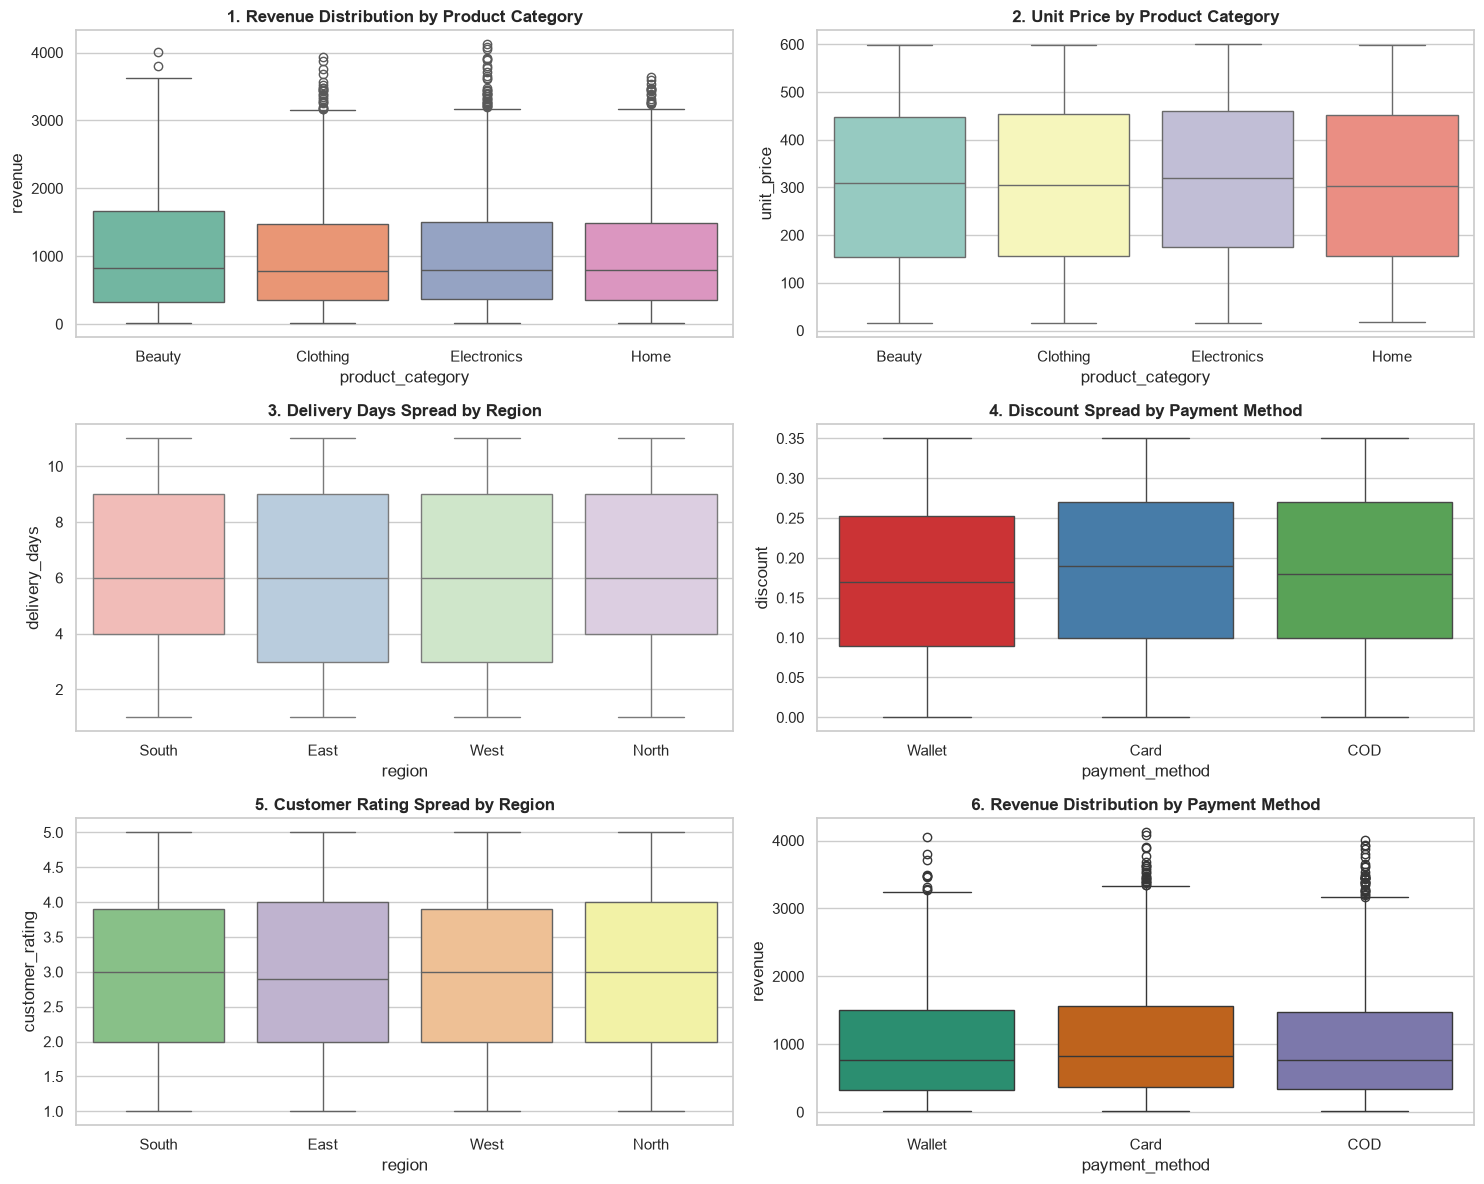

In [16]:
# ==========================================
# BOXPLOTS
# ==========================================

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# Plot 1: Revenue by Product Category
sns.boxplot(data=df, x='product_category', y='revenue', palette='Set2', ax=axes[0,0])
axes[0,0].set_title('1. Revenue Distribution by Product Category', fontweight='bold')

# Plot 2: Unit Price by Product Category
sns.boxplot(data=df, x='product_category', y='unit_price', palette='Set3', ax=axes[0,1])
axes[0,1].set_title('2. Unit Price by Product Category', fontweight='bold')

# Plot 3: Delivery Days by Region
sns.boxplot(data=df, x='region', y='delivery_days', palette='Pastel1', ax=axes[1,0])
axes[1,0].set_title('3. Delivery Days Spread by Region', fontweight='bold')

# Plot 4: Discount by Payment Method
sns.boxplot(data=df, x='payment_method', y='discount', palette='Set1', ax=axes[1,1])
axes[1,1].set_title('4. Discount Spread by Payment Method', fontweight='bold')

# Plot 5: Customer Rating by Region
sns.boxplot(data=df, x='region', y='customer_rating', palette='Accent', ax=axes[2,0])
axes[2,0].set_title('5. Customer Rating Spread by Region', fontweight='bold')

# Plot 6: Revenue by Payment Method
sns.boxplot(data=df, x='payment_method', y='revenue', palette='Dark2', ax=axes[2,1])
axes[2,1].set_title('6. Revenue Distribution by Payment Method', fontweight='bold')

plt.tight_layout()
plt.show()

C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\2499023840.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='product_category', y='revenue', palette='Pastel2', inner='quartile', ax=axes[0,0])
C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\2499023840.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='region', y='unit_price', palette='Set2', inner='quartile', ax=axes[0,1])
C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\2499023840.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

 

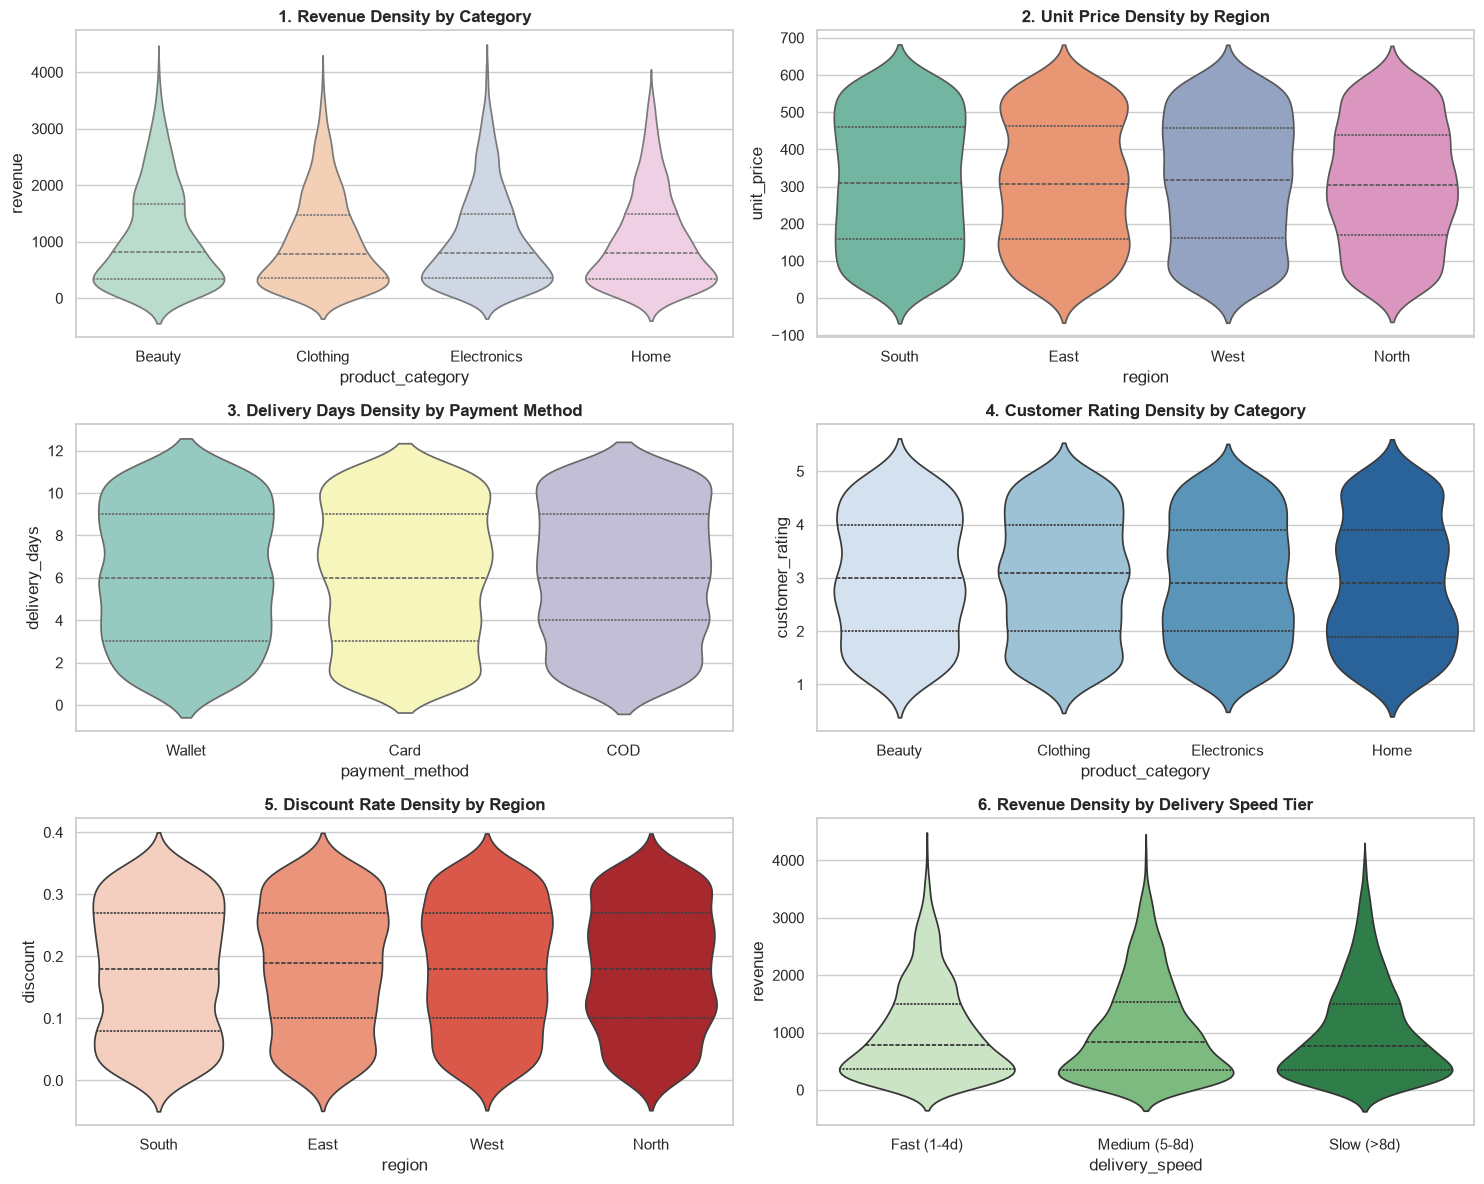

In [17]:
# ==========================================
# VIOLINPLOTS
# ==========================================

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# Plot 1: Revenue Kernel Density by Product Category
sns.violinplot(data=df, x='product_category', y='revenue', palette='Pastel2', inner='quartile', ax=axes[0,0])
axes[0,0].set_title('1. Revenue Density by Category', fontweight='bold')

# Plot 2: Unit Price Density by Region
sns.violinplot(data=df, x='region', y='unit_price', palette='Set2', inner='quartile', ax=axes[0,1])
axes[0,1].set_title('2. Unit Price Density by Region', fontweight='bold')

# Plot 3: Delivery Days Density by Payment Method
sns.violinplot(data=df, x='payment_method', y='delivery_days', palette='Set3', inner='quartile', ax=axes[1,0])
axes[1,0].set_title('3. Delivery Days Density by Payment Method', fontweight='bold')

# Plot 4: Customer Rating Density by Product Category
sns.violinplot(data=df, x='product_category', y='customer_rating', palette='Blues', inner='quartile', ax=axes[1,1])
axes[1,1].set_title('4. Customer Rating Density by Category', fontweight='bold')

# Plot 5: Discount Density by Region
sns.violinplot(data=df, x='region', y='discount', palette='Reds', inner='quartile', ax=axes[2,0])
axes[2,0].set_title('5. Discount Rate Density by Region', fontweight='bold')

# Plot 6: Revenue Density by Delivery Speed Tier
sns.violinplot(data=df, x='delivery_speed', y='revenue', palette='Greens', inner='quartile', ax=axes[2,1])
axes[2,1].set_title('6. Revenue Density by Delivery Speed Tier', fontweight='bold')

plt.tight_layout()
plt.show()

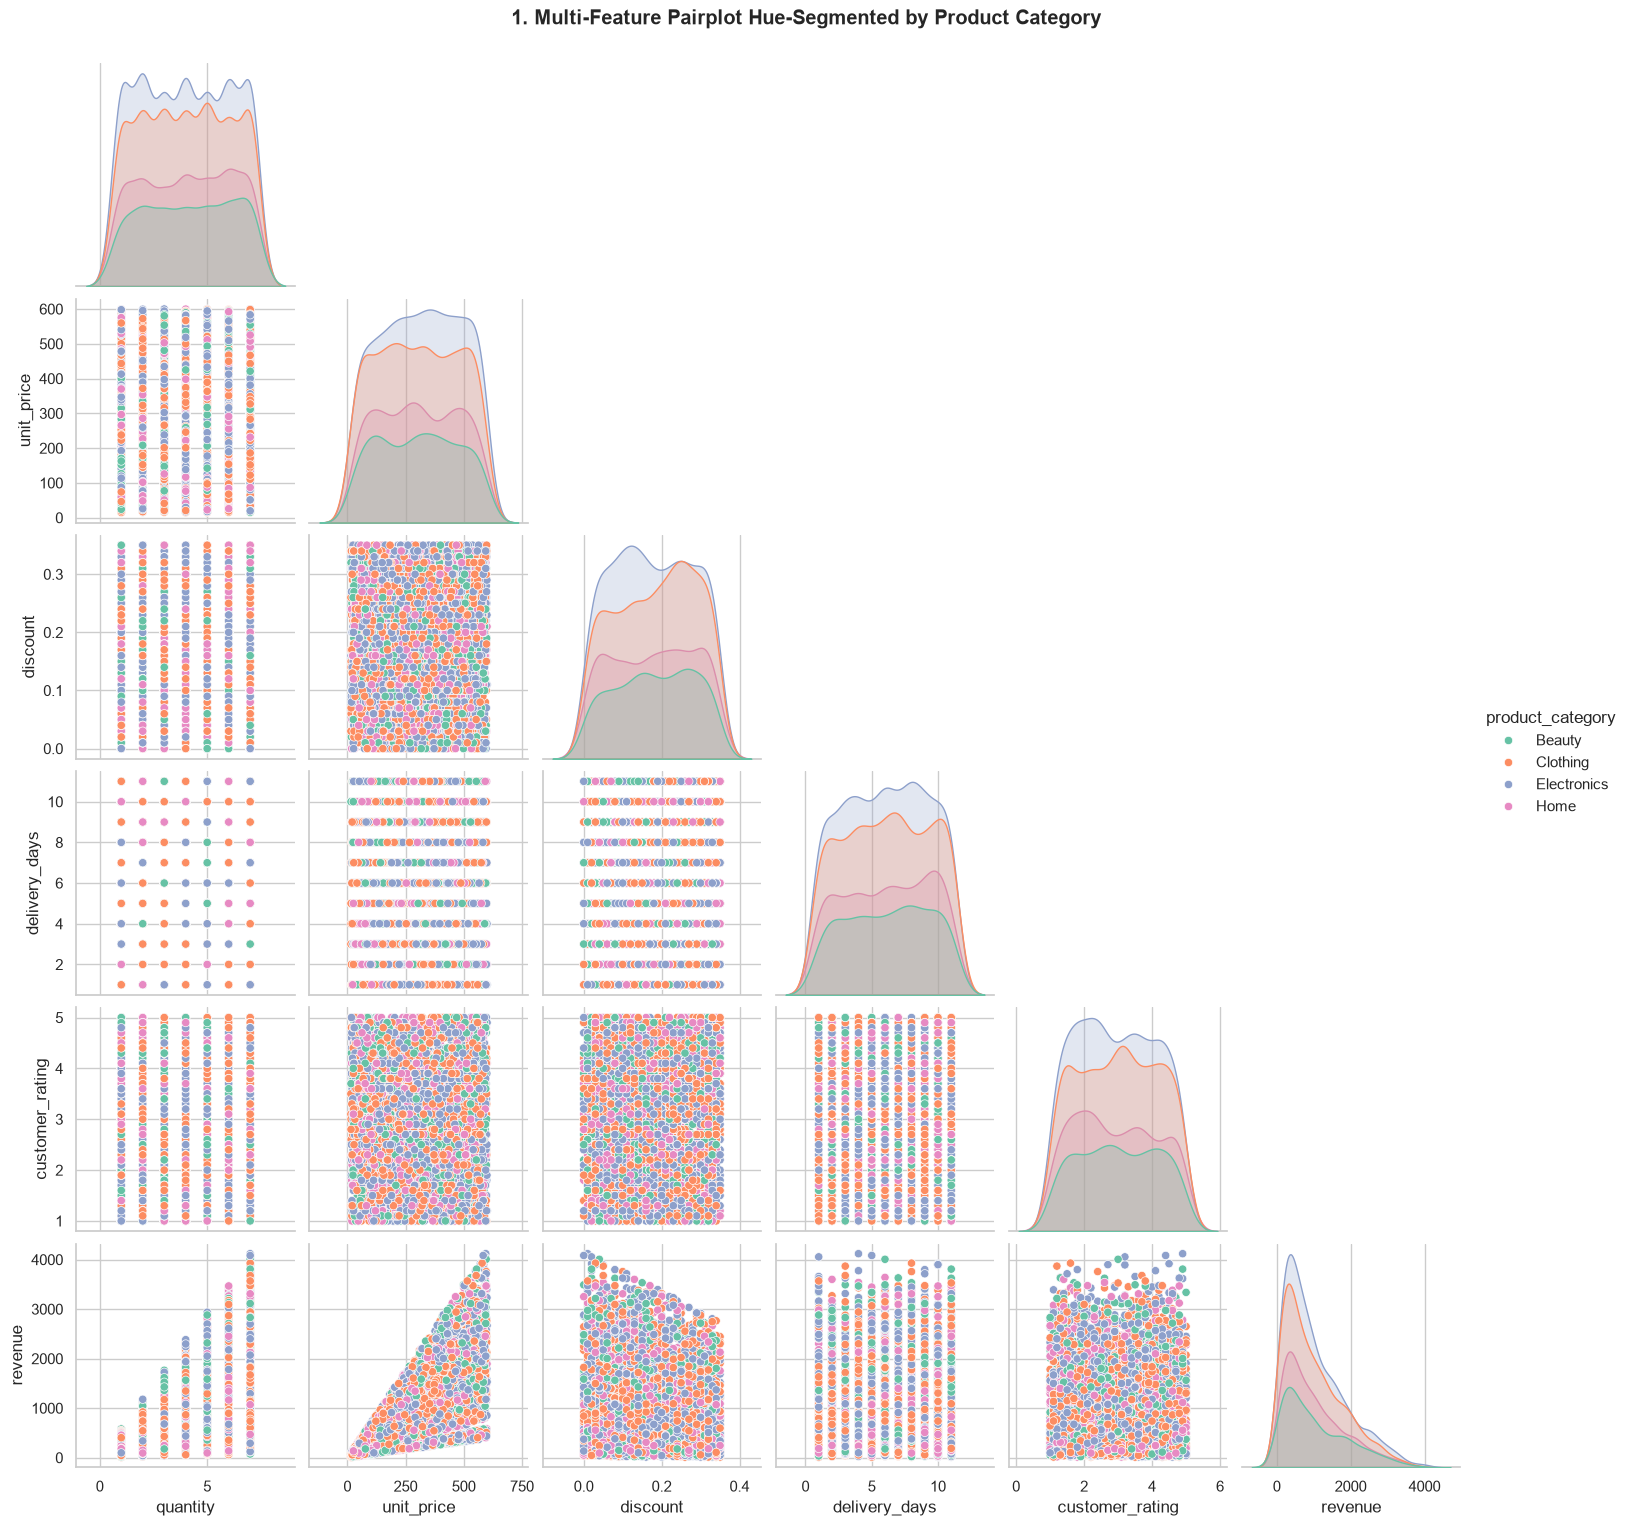

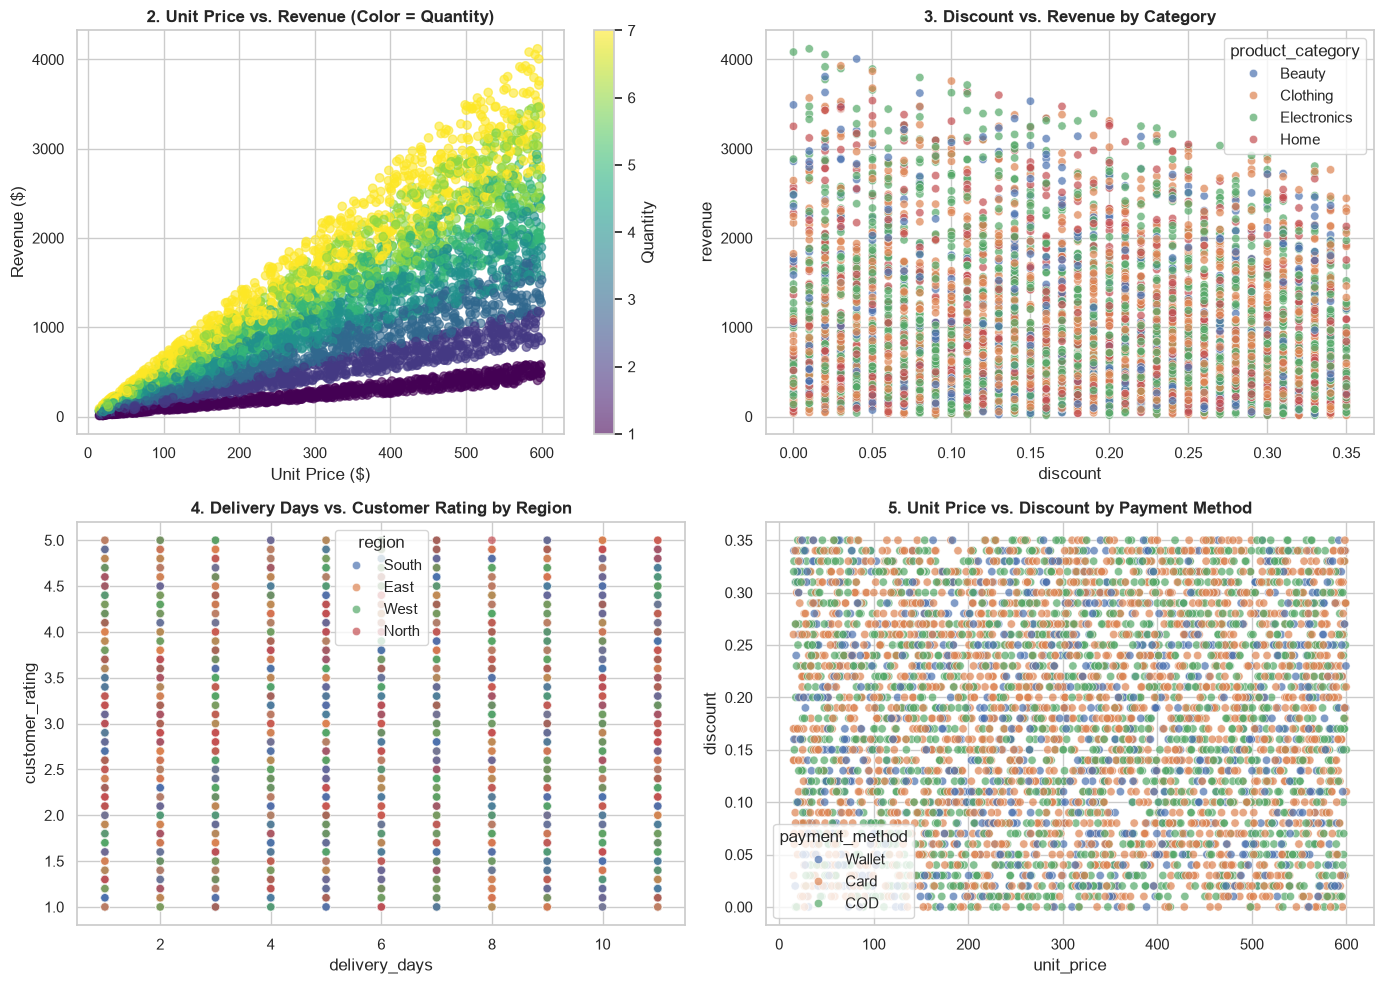

In [18]:
# ==========================================
# PAIRPLOT & SCATTERPLOTS
# ==========================================

# 1. Pairplot across primary continuous numerical features segmented by product_category
num_cols = ['quantity', 'unit_price', 'discount', 'delivery_days', 'customer_rating', 'revenue', 'product_category']
pair_plot = sns.pairplot(df[num_cols], hue='product_category', corner=True, palette='Set2')
pair_plot.fig.suptitle('1. Multi-Feature Pairplot Hue-Segmented by Product Category', y=1.02, fontweight='bold')
plt.show()

# 2. Targeted Scatterplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Scatter 1: Unit Price vs Revenue (Colored by Quantity)
scatter1 = axes[0,0].scatter(df['unit_price'], df['revenue'], c=df['quantity'], cmap='viridis', alpha=0.6)
axes[0,0].set_title('2. Unit Price vs. Revenue (Color = Quantity)', fontweight='bold')
axes[0,0].set_xlabel('Unit Price ($)')
axes[0,0].set_ylabel('Revenue ($)')
fig.colorbar(scatter1, ax=axes[0,0], label='Quantity')

# Scatter 2: Discount vs Revenue
sns.scatterplot(data=df, x='discount', y='revenue', hue='product_category', alpha=0.7, ax=axes[0,1])
axes[0,1].set_title('3. Discount vs. Revenue by Category', fontweight='bold')

# Scatter 3: Delivery Days vs Customer Rating
sns.scatterplot(data=df, x='delivery_days', y='customer_rating', hue='region', alpha=0.7, ax=axes[1,0])
axes[1,0].set_title('4. Delivery Days vs. Customer Rating by Region', fontweight='bold')

# Scatter 4: Unit Price vs Discount
sns.scatterplot(data=df, x='unit_price', y='discount', hue='payment_method', alpha=0.7, ax=axes[1,1])
axes[1,1].set_title('5. Unit Price vs. Discount by Payment Method', fontweight='bold')

plt.tight_layout()
plt.show()

C:\Users\MICHAEL LAWRENCE\AppData\Local\Temp\ipykernel_17324\3119650268.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='product_category', y='revenue_per_item', palette='Set2', ax=axes[2,1])


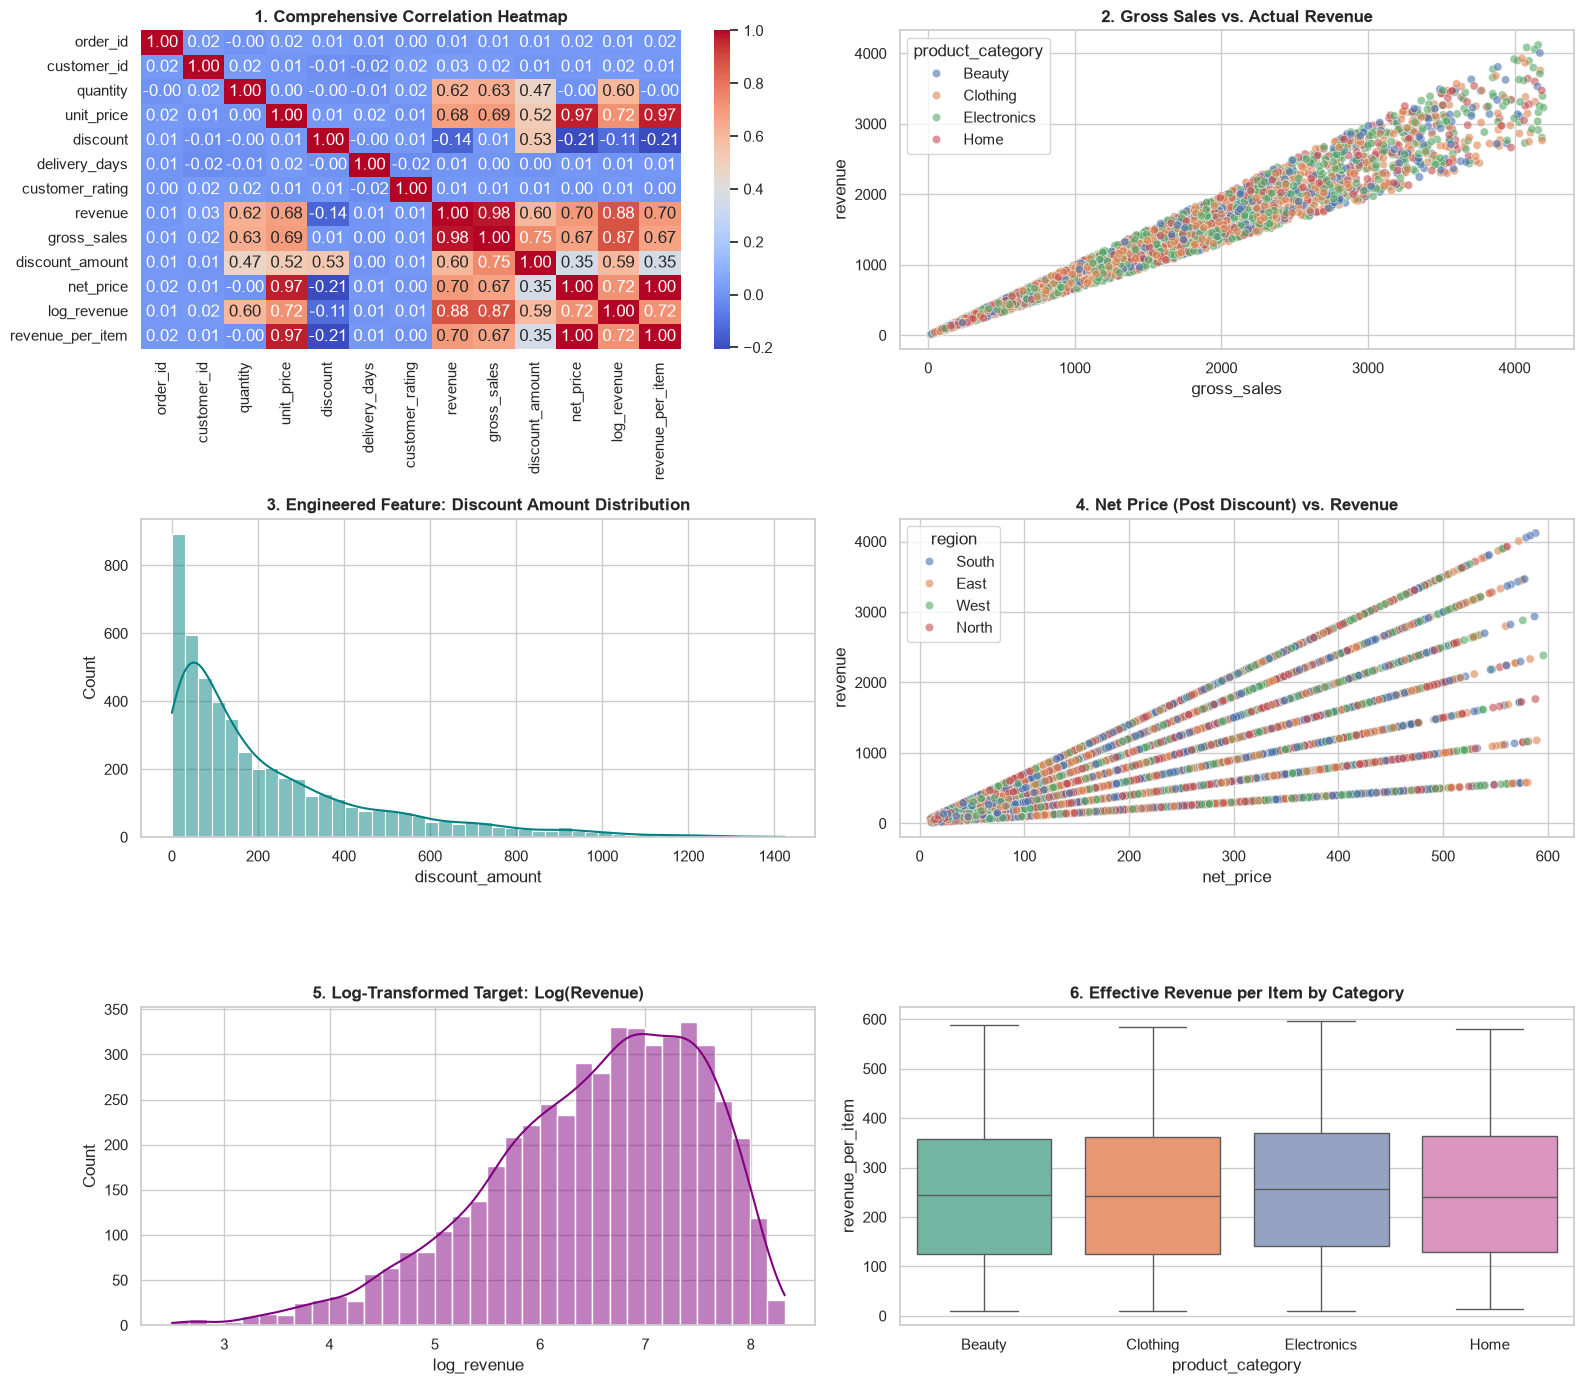

In [19]:
# ==========================================
# FEATURE ENGINEERING PLOTS
# ==========================================

# Derived Feature Calculations:
df['gross_sales'] = df['quantity'] * df['unit_price']
df['discount_amount'] = df['gross_sales'] * df['discount']
df['net_price'] = df['unit_price'] * (1 - df['discount'])
df['log_revenue'] = np.log1p(df['revenue'])
df['revenue_per_item'] = df['revenue'] / df['quantity']
df['order_year_month'] = df['order_date'].dt.to_period('M').astype(str)

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

# Plot 1: Correlation Heatmap
num_df = df.select_dtypes(include=[np.number])
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[0,0], cbar=True)
axes[0,0].set_title('1. Comprehensive Correlation Heatmap', fontweight='bold')

# Plot 2: Gross Sales vs Actual Revenue
sns.scatterplot(data=df, x='gross_sales', y='revenue', hue='product_category', ax=axes[0,1], alpha=0.6)
axes[0,1].set_title('2. Gross Sales vs. Actual Revenue', fontweight='bold')

# Plot 3: Discount Amount Distribution
sns.histplot(df['discount_amount'], kde=True, color='teal', ax=axes[1,0])
axes[1,0].set_title('3. Engineered Feature: Discount Amount Distribution', fontweight='bold')

# Plot 4: Net Price vs Revenue
sns.scatterplot(data=df, x='net_price', y='revenue', hue='region', ax=axes[1,1], alpha=0.6)
axes[1,1].set_title('4. Net Price (Post Discount) vs. Revenue', fontweight='bold')

# Plot 5: Log-Transformed Revenue Distribution
sns.histplot(df['log_revenue'], kde=True, color='purple', ax=axes[2,0])
axes[2,0].set_title('5. Log-Transformed Target: Log(Revenue)', fontweight='bold')

# Plot 6: Revenue per Item by Product Category
sns.boxplot(data=df, x='product_category', y='revenue_per_item', palette='Set2', ax=axes[2,1])
axes[2,1].set_title('6. Effective Revenue per Item by Category', fontweight='bold')

plt.tight_layout()
plt.show()

In [20]:
# ==========================================
# TIME SERIES & FORECAST PLOTS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 1. Prepare Monthly Resampled Time Series Data
df = pd.read_csv('dataset_path')
df['order_date'] = pd.to_datetime(df['order_date'])
df_ts = df.set_index('order_date').resample('ME')['revenue'].sum().asfreq('ME').fillna(method='ffill')

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

# Plot 1: Historical Monthly Revenue Trend & Moving Averages
axes[0, 0].plot(df_ts.index, df_ts.values, label='Monthly Revenue', color='navy', lw=2)
axes[0, 0].plot(df_ts.rolling(window=12).mean(), label='12-Month Moving Avg', color='crimson', lw=2, linestyle='--')
axes[0, 0].set_title('1. Monthly Revenue Trend with 12-Month Moving Average', fontweight='bold')
axes[0, 0].set_ylabel('Revenue ($)')
axes[0, 0].legend()

# Plot 2: STL Trend Decomposition
decomp = seasonal_decompose(df_ts, model='additive', period=12)
axes[0, 1].plot(decomp.trend, color='darkgreen', lw=2)
axes[0, 1].set_title('2. Extracted Long-Term Trend Component (STL)', fontweight='bold')
axes[0, 1].set_ylabel('Trend ($)')

# Plot 3: STL Seasonal Component
axes[1, 0].plot(decomp.seasonal, color='darkorange', lw=2)
axes[1, 0].set_title('3. Extracted Yearly Seasonal Component (STL)', fontweight='bold')
axes[1, 0].set_ylabel('Seasonal Variation')

# Plot 4: Autocorrelation Function (ACF)
plot_acf(df_ts, ax=axes[1, 1], lags=24, color='purple')
axes[1, 1].set_title('4. Autocorrelation Function (ACF - 24 Lags)', fontweight='bold')

# Plot 5: Category-Wise Monthly Growth Curves
df_cat_ts = df.groupby([pd.Grouper(key='order_date', freq='ME'), 'product_category'])['revenue'].sum().unstack()
df_cat_ts.plot(ax=axes[2, 0], lw=1.5)
axes[2, 0].set_title('5. Multi-Category Monthly Growth Curves', fontweight='bold')
axes[2, 0].set_ylabel('Revenue ($)')

# Plot 6: Holt-Winters 5-Year (60-Month) Future Forecast
model_hw = ExponentialSmoothing(df_ts, seasonal='add', seasonal_periods=12, trend='add').fit()
forecast_5yr = model_hw.forecast(60) # 5 years = 60 months

axes[2, 1].plot(df_ts.index, df_ts.values, label='Historical Revenue', color='navy', lw=2)
axes[2, 1].plot(forecast_5yr.index, forecast_5yr.values, label='5-Year Projected Forecast', color='magenta', lw=2, linestyle='--')
axes[2, 1].set_title('6. 5-Year Future Revenue Forecast (Holt-Winters ES)', fontweight='bold')
axes[2, 1].set_ylabel('Revenue ($)')
axes[2, 1].legend()

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'statsmodels'

/tmp/ipykernel_58/3885687659.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_df, x='R2', y='Model', palette='viridis', ax=axes[0,0])
/tmp/ipykernel_58/3885687659.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_df, x='RMSE', y='Model', palette='magma', ax=axes[0,1])
/tmp/ipykernel_58/3885687659.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_df, x='MAE', y='Model', palette='rocket', ax=axes[2,1])


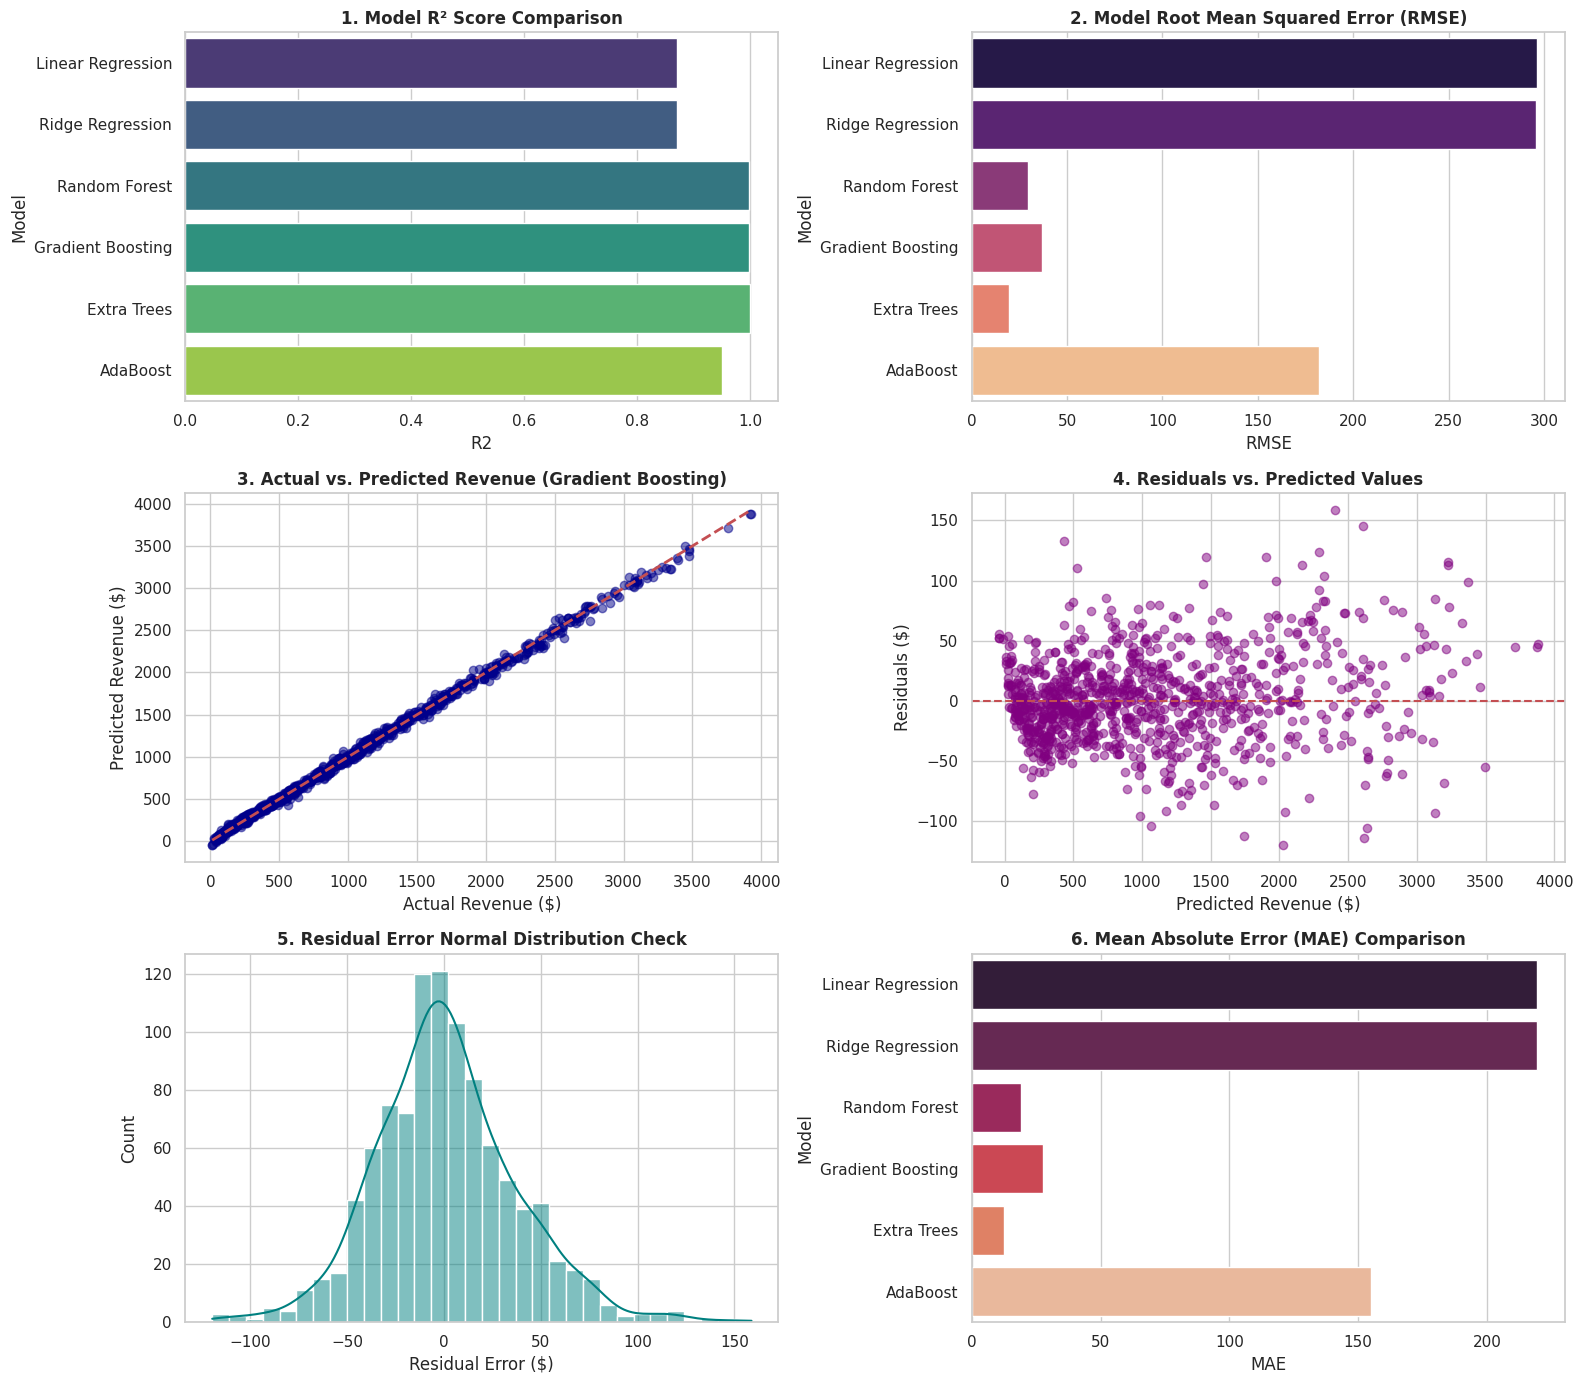

In [ ]:
# ==========================================
# MACHINE LEARNING MODELS & EVALUATION PLOTS
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor, AdaBoostRegressor

# 1. Feature Selection & Preprocessing Pipeline Setup
X = df[['product_category', 'region', 'payment_method', 'quantity', 'unit_price', 'discount', 'delivery_days', 'customer_rating']]
y = df['revenue']

cat_features = ['product_category', 'region', 'payment_method']
num_features = ['quantity', 'unit_price', 'discount', 'delivery_days', 'customer_rating']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first'), cat_features),
        ('num', 'passthrough', num_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'Extra Trees': ExtraTreesRegressor(n_estimators=100, random_state=42),
    'AdaBoost': AdaBoostRegressor(n_estimators=100, random_state=42)
}

results = []
predictions = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    
    results.append({'Model': name, 'R2': r2, 'RMSE': rmse, 'MAE': mae})
    predictions[name] = y_pred

res_df = pd.DataFrame(results)

# Best Model Extraction (Gradient Boosting)
best_model_name = 'Gradient Boosting'
best_preds = predictions[best_model_name]
residuals = y_test - best_preds

# Evaluation Plots
fig, axes = plt.subplots(3, 2, figsize=(16, 14))

# Plot 1: R2 Score Model Comparison
sns.barplot(data=res_df, x='R2', y='Model', palette='viridis', ax=axes[0,0])
axes[0,0].set_title('1. Model R² Score Comparison', fontweight='bold')
axes[0,0].set_xlim(0, 1.05)

# Plot 2: RMSE Model Comparison
sns.barplot(data=res_df, x='RMSE', y='Model', palette='magma', ax=axes[0,1])
axes[0,1].set_title('2. Model Root Mean Squared Error (RMSE)', fontweight='bold')

# Plot 3: Actual vs Predicted Revenue (Best Model)
axes[1,0].scatter(y_test, best_preds, alpha=0.5, color='darkblue')
axes[1,0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1,0].set_title(f'3. Actual vs. Predicted Revenue ({best_model_name})', fontweight='bold')
axes[1,0].set_xlabel('Actual Revenue ($)')
axes[1,0].set_ylabel('Predicted Revenue ($)')

# Plot 4: Residuals vs Predicted Values
axes[1,1].scatter(best_preds, residuals, alpha=0.5, color='purple')
axes[1,1].axhline(y=0, color='r', linestyle='--')
axes[1,1].set_title('4. Residuals vs. Predicted Values', fontweight='bold')
axes[1,1].set_xlabel('Predicted Revenue ($)')
axes[1,1].set_ylabel('Residuals ($)')

# Plot 5: Residual Error Distribution
sns.histplot(residuals, kde=True, color='teal', ax=axes[2,0])
axes[2,0].set_title('5. Residual Error Normal Distribution Check', fontweight='bold')
axes[2,0].set_xlabel('Residual Error ($)')

# Plot 6: MAE Model Comparison
sns.barplot(data=res_df, x='MAE', y='Model', palette='rocket', ax=axes[2,1])
axes[2,1].set_title('6. Mean Absolute Error (MAE) Comparison', fontweight='bold')

plt.tight_layout()
plt.show()

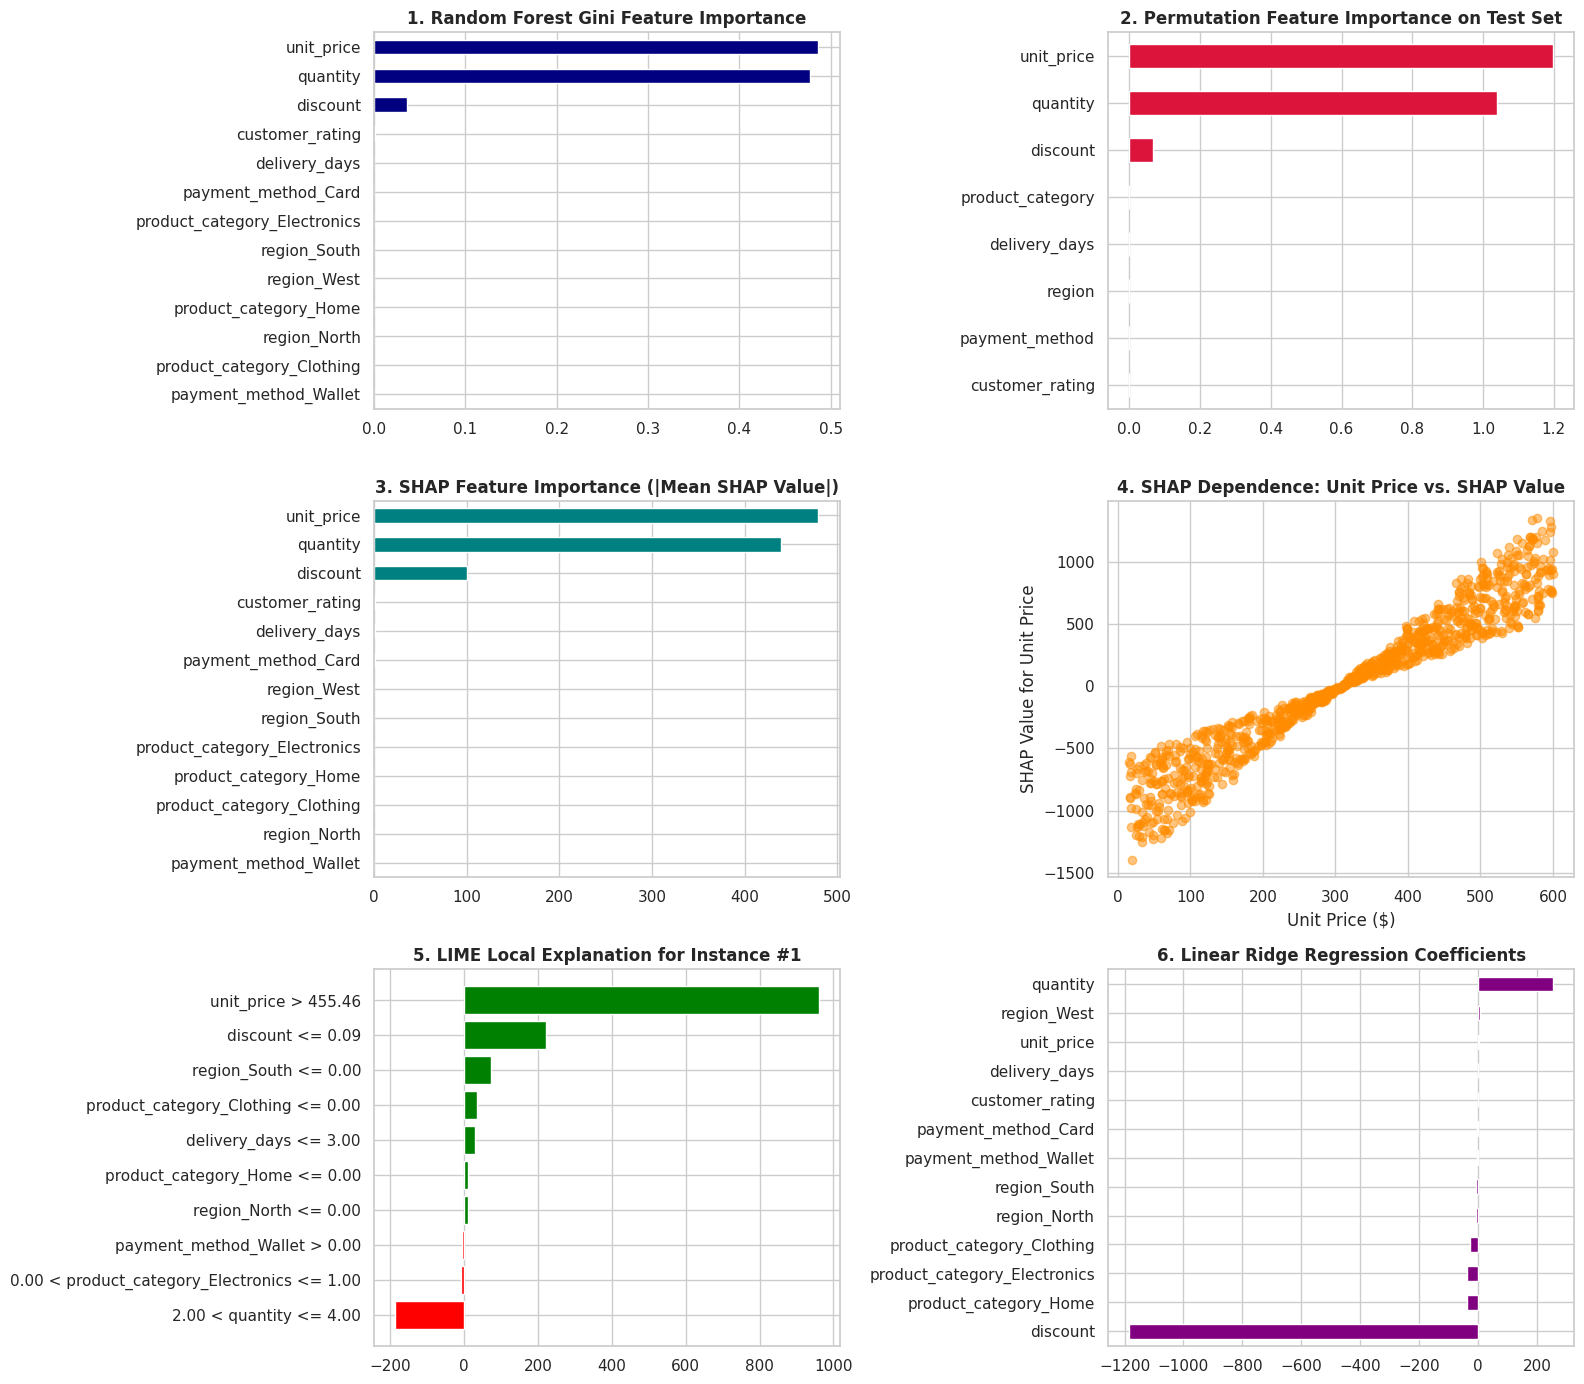

In [ ]:
# ==========================================
# FEATURE IMPORTANCE PLOTS
# ==========================================

import shap
from lime import lime_tabular

# Fit pipeline and fit encoded transformed feature arrays
rf_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))])
rf_pipeline.fit(X_train, y_train)

# Obtain feature names post One-Hot Encoding
ohe_cols = list(rf_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(cat_features))
all_feature_names = ohe_cols + num_features

X_train_trans = rf_pipeline.named_steps['preprocessor'].transform(X_train)
X_test_trans = rf_pipeline.named_steps['preprocessor'].transform(X_test)

fitted_rf = rf_pipeline.named_steps['regressor']

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

# Plot 1: Tree-Based Feature Importance
importances = fitted_rf.feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=True)
feat_imp.plot(kind='barh', color='navy', ax=axes[0,0])
axes[0,0].set_title('1. Random Forest Gini Feature Importance', fontweight='bold')

# Plot 2: Permutation Feature Importance
from sklearn.inspection import permutation_importance
perm_imp = permutation_importance(rf_pipeline, X_test, y_test, n_repeats=10, random_state=42)
perm_series = pd.Series(perm_imp.importances_mean, index=X.columns).sort_values(ascending=True)
perm_series.plot(kind='barh', color='crimson', ax=axes[0,1])
axes[0,1].set_title('2. Permutation Feature Importance on Test Set', fontweight='bold')

# Plot 3: SHAP Summary Plot (Bar Format)
explainer = shap.TreeExplainer(fitted_rf)
shap_values = explainer.shap_values(X_test_trans)

shap_mean = np.abs(shap_values).mean(axis=0)
shap_series = pd.Series(shap_mean, index=all_feature_names).sort_values(ascending=True)
shap_series.plot(kind='barh', color='teal', ax=axes[1,0])
axes[1,0].set_title('3. SHAP Feature Importance (|Mean SHAP Value|)', fontweight='bold')

# Plot 4: SHAP Dependence Plot for Unit Price
unit_price_idx = all_feature_names.index('unit_price')
axes[1,1].scatter(X_test_trans[:, unit_price_idx], shap_values[:, unit_price_idx], alpha=0.5, color='darkorange')
axes[1,1].set_title('4. SHAP Dependence: Unit Price vs. SHAP Value', fontweight='bold')
axes[1,1].set_xlabel('Unit Price ($)')
axes[1,1].set_ylabel('SHAP Value for Unit Price')

# Plot 5: LIME Explanation for Single Instance
lime_explainer = lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train_trans),
    feature_names=all_feature_names,
    class_names=['revenue'],
    mode='regression'
)
exp = lime_explainer.explain_instance(X_test_trans[0], fitted_rf.predict)
lime_list = exp.as_list()
lime_df = pd.DataFrame(lime_list, columns=['Feature_Condition', 'Weight']).sort_values('Weight')
axes[2,0].barh(lime_df['Feature_Condition'], lime_df['Weight'], color=np.where(lime_df['Weight']>0, 'green', 'red'))
axes[2,0].set_title('5. LIME Local Explanation for Instance #1', fontweight='bold')

# Plot 6: Linear Regression Coefficients
lr_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', Ridge())])
lr_pipeline.fit(X_train, y_train)
lr_coefs = pd.Series(lr_pipeline.named_steps['regressor'].coef_, index=all_feature_names).sort_values(ascending=True)
lr_coefs.plot(kind='barh', color='purple', ax=axes[2,1])
axes[2,1].set_title('6. Linear Ridge Regression Coefficients', fontweight='bold')

plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


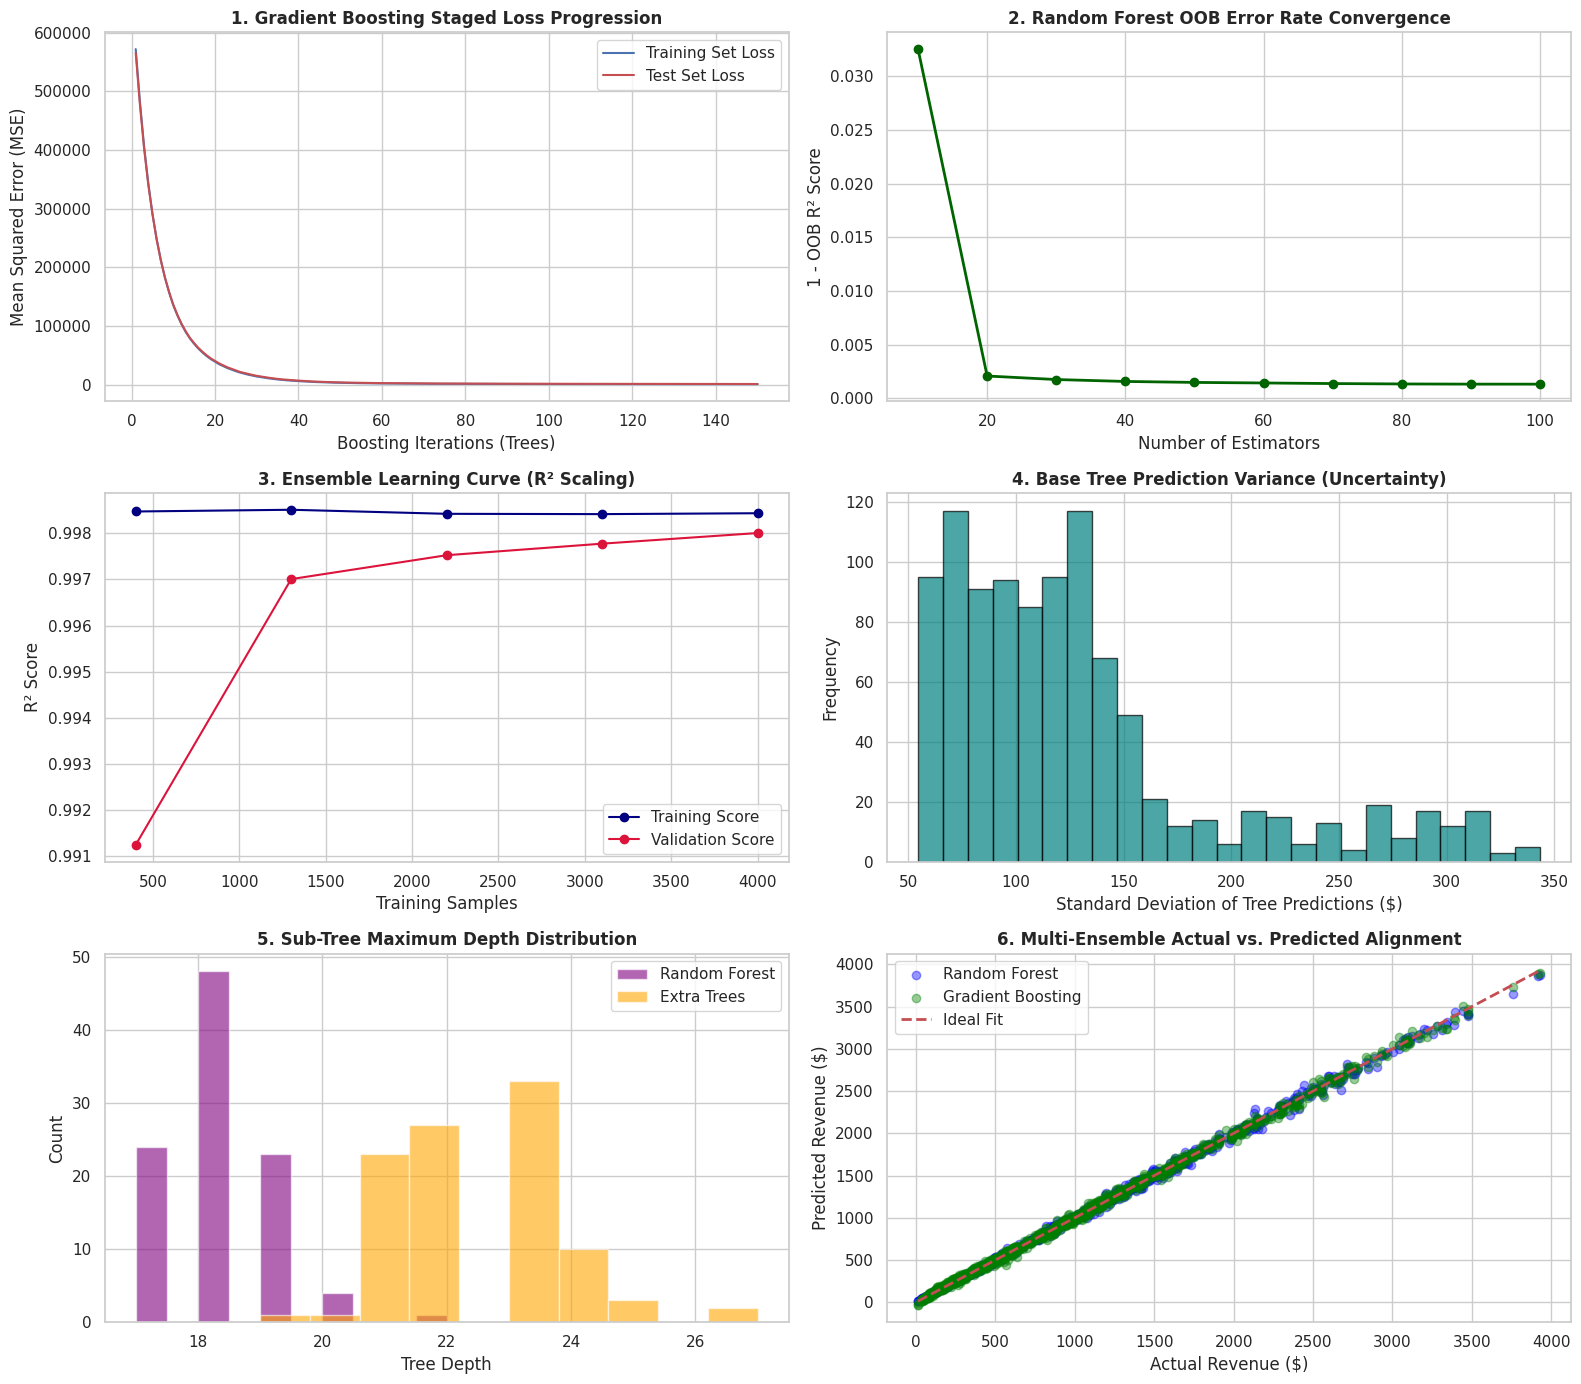

In [ ]:
# ==========================================
# ENSEMBLE MODELS & PLOTS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, ExtraTreesRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error

# 1. Load Dataset & Prepare Feature Matrices
df = pd.read_csv('dataset_path')
X = df[['product_category', 'region', 'payment_method', 'quantity', 'unit_price', 'discount', 'delivery_days', 'customer_rating']]
y = df['revenue']

# Categorical Feature Transformation
ct = ColumnTransformer(
    [('cat', OneHotEncoder(drop='first'), ['product_category', 'region', 'payment_method'])],
    remainder='passthrough'
)
X_trans = ct.fit_transform(X)

# Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X_trans, y, test_size=0.2, random_state=42)

# Set Seaborn Visual Theme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 14))

# -------------------------------------------------------------------------
# Plot 1: Gradient Boosting Staged Deviance (Loss Progression)
# -------------------------------------------------------------------------
# Description: Evaluates MSE loss reduction at each boosting iteration (tree addition)
# to detect model convergence and overfitting boundaries.
gbr = GradientBoostingRegressor(n_estimators=150, random_state=42)
gbr.fit(X_train, y_train)

test_deviance = np.zeros(150, dtype=np.float64)
for i, y_pred in enumerate(gbr.staged_predict(X_test)):
    test_deviance[i] = mean_squared_error(y_test, y_pred)

axes[0, 0].plot(np.arange(150) + 1, gbr.train_score_, 'b-', label='Training Set Loss')
axes[0, 0].plot(np.arange(150) + 1, test_deviance, 'r-', label='Test Set Loss')
axes[0, 0].set_title('1. Gradient Boosting Staged Loss Progression', fontweight='bold')
axes[0, 0].set_xlabel('Boosting Iterations (Trees)')
axes[0, 0].set_ylabel('Mean Squared Error (MSE)')
axes[0, 0].legend()

# -------------------------------------------------------------------------
# Plot 2: Random Forest Out-of-Bag (OOB) Error Rate Convergence
# -------------------------------------------------------------------------
# Description: Tracks Out-Of-Bag (1 - OOB R²) error convergence as the number 
# of bootstrapped decision trees grows from 10 to 100.
oob_errors = []
tree_counts = range(10, 101, 10)
for n in tree_counts:
    rf_oob = RandomForestRegressor(n_estimators=n, oob_score=True, random_state=42, bootstrap=True)
    rf_oob.fit(X_train, y_train)
    oob_errors.append(1 - rf_oob.oob_score_)

axes[0, 1].plot(tree_counts, oob_errors, marker='o', color='darkgreen', lw=2)
axes[0, 1].set_title('2. Random Forest OOB Error Rate Convergence', fontweight='bold')
axes[0, 1].set_xlabel('Number of Estimators')
axes[0, 1].set_ylabel('1 - OOB R² Score')

# -------------------------------------------------------------------------
# Plot 3: Ensemble Learning Curve (Data Size Scaling)
# -------------------------------------------------------------------------
# Description: Measures model generalization capability by comparing cross-validated 
# training and validation R² scores across expanding dataset sample sizes.
train_sizes, train_scores, val_scores = learning_curve(
    GradientBoostingRegressor(n_estimators=100, random_state=42), 
    X_trans, y, cv=5, train_sizes=np.linspace(0.1, 1.0, 5), scoring='r2'
)
axes[1, 0].plot(train_sizes, train_scores.mean(axis=1), 'o-', color='navy', label='Training Score')
axes[1, 0].plot(train_sizes, val_scores.mean(axis=1), 'o-', color='crimson', label='Validation Score')
axes[1, 0].set_title('3. Ensemble Learning Curve (R² Scaling)', fontweight='bold')
axes[1, 0].set_xlabel('Training Samples')
axes[1, 0].set_ylabel('R² Score')
axes[1, 0].legend()

# -------------------------------------------------------------------------
# Plot 4: Individual Sub-Tree Prediction Uncertainty
# -------------------------------------------------------------------------
# Description: Plots the distribution of standard deviations across individual base 
# tree predictions within the ensemble to measure model prediction variance.
tree_preds = np.array([tree[0].predict(X_test) for tree in gbr.estimators_])
pred_std = tree_preds.std(axis=0)

axes[1, 1].hist(pred_std, bins=25, color='teal', edgecolor='black', alpha=0.7)
axes[1, 1].set_title('4. Base Tree Prediction Variance (Uncertainty)', fontweight='bold')
axes[1, 1].set_xlabel('Standard Deviation of Tree Predictions ($)')
axes[1, 1].set_ylabel('Frequency')

# -------------------------------------------------------------------------
# Plot 5: Maximum Sub-Tree Depth Comparison
# -------------------------------------------------------------------------
# Description: Compares tree depth distributions between Random Forest and Extra 
# Trees to inspect model structural complexity.
rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)
et = ExtraTreesRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)

rf_depths = [estimator.get_depth() for estimator in rf.estimators_]
et_depths = [estimator.get_depth() for estimator in et.estimators_]

axes[2, 0].hist(rf_depths, alpha=0.6, label='Random Forest', color='purple', bins=10)
axes[2, 0].hist(et_depths, alpha=0.6, label='Extra Trees', color='orange', bins=10)
axes[2, 0].set_title('5. Sub-Tree Maximum Depth Distribution', fontweight='bold')
axes[2, 0].set_xlabel('Tree Depth')
axes[2, 0].set_ylabel('Count')
axes[2, 0].legend()

# -------------------------------------------------------------------------
# Plot 6: Multi-Ensemble Actual vs. Predicted Alignment
# -------------------------------------------------------------------------
# Description: Overlays actual test target values against predicted revenue values 
# for Random Forest and Gradient Boosting relative to the ideal identity line ($y=x$).
rf_preds = rf.predict(X_test)
gb_preds = gbr.predict(X_test)

axes[2, 1].scatter(y_test, rf_preds, alpha=0.4, label='Random Forest', color='blue')
axes[2, 1].scatter(y_test, gb_preds, alpha=0.4, label='Gradient Boosting', color='green')
axes[2, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
axes[2, 1].set_title('6. Multi-Ensemble Actual vs. Predicted Alignment', fontweight='bold')
axes[2, 1].set_xlabel('Actual Revenue ($)')
axes[2, 1].set_ylabel('Predicted Revenue ($)')
axes[2, 1].legend()

plt.tight_layout()
plt.show()

/tmp/ipykernel_58/3004570776.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2, 0].boxplot(z_scores.values, labels=z_scores.columns)
/tmp/ipykernel_58/3004570776.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='total_outlier_flags', palette='Reds', ax=axes[2, 1])


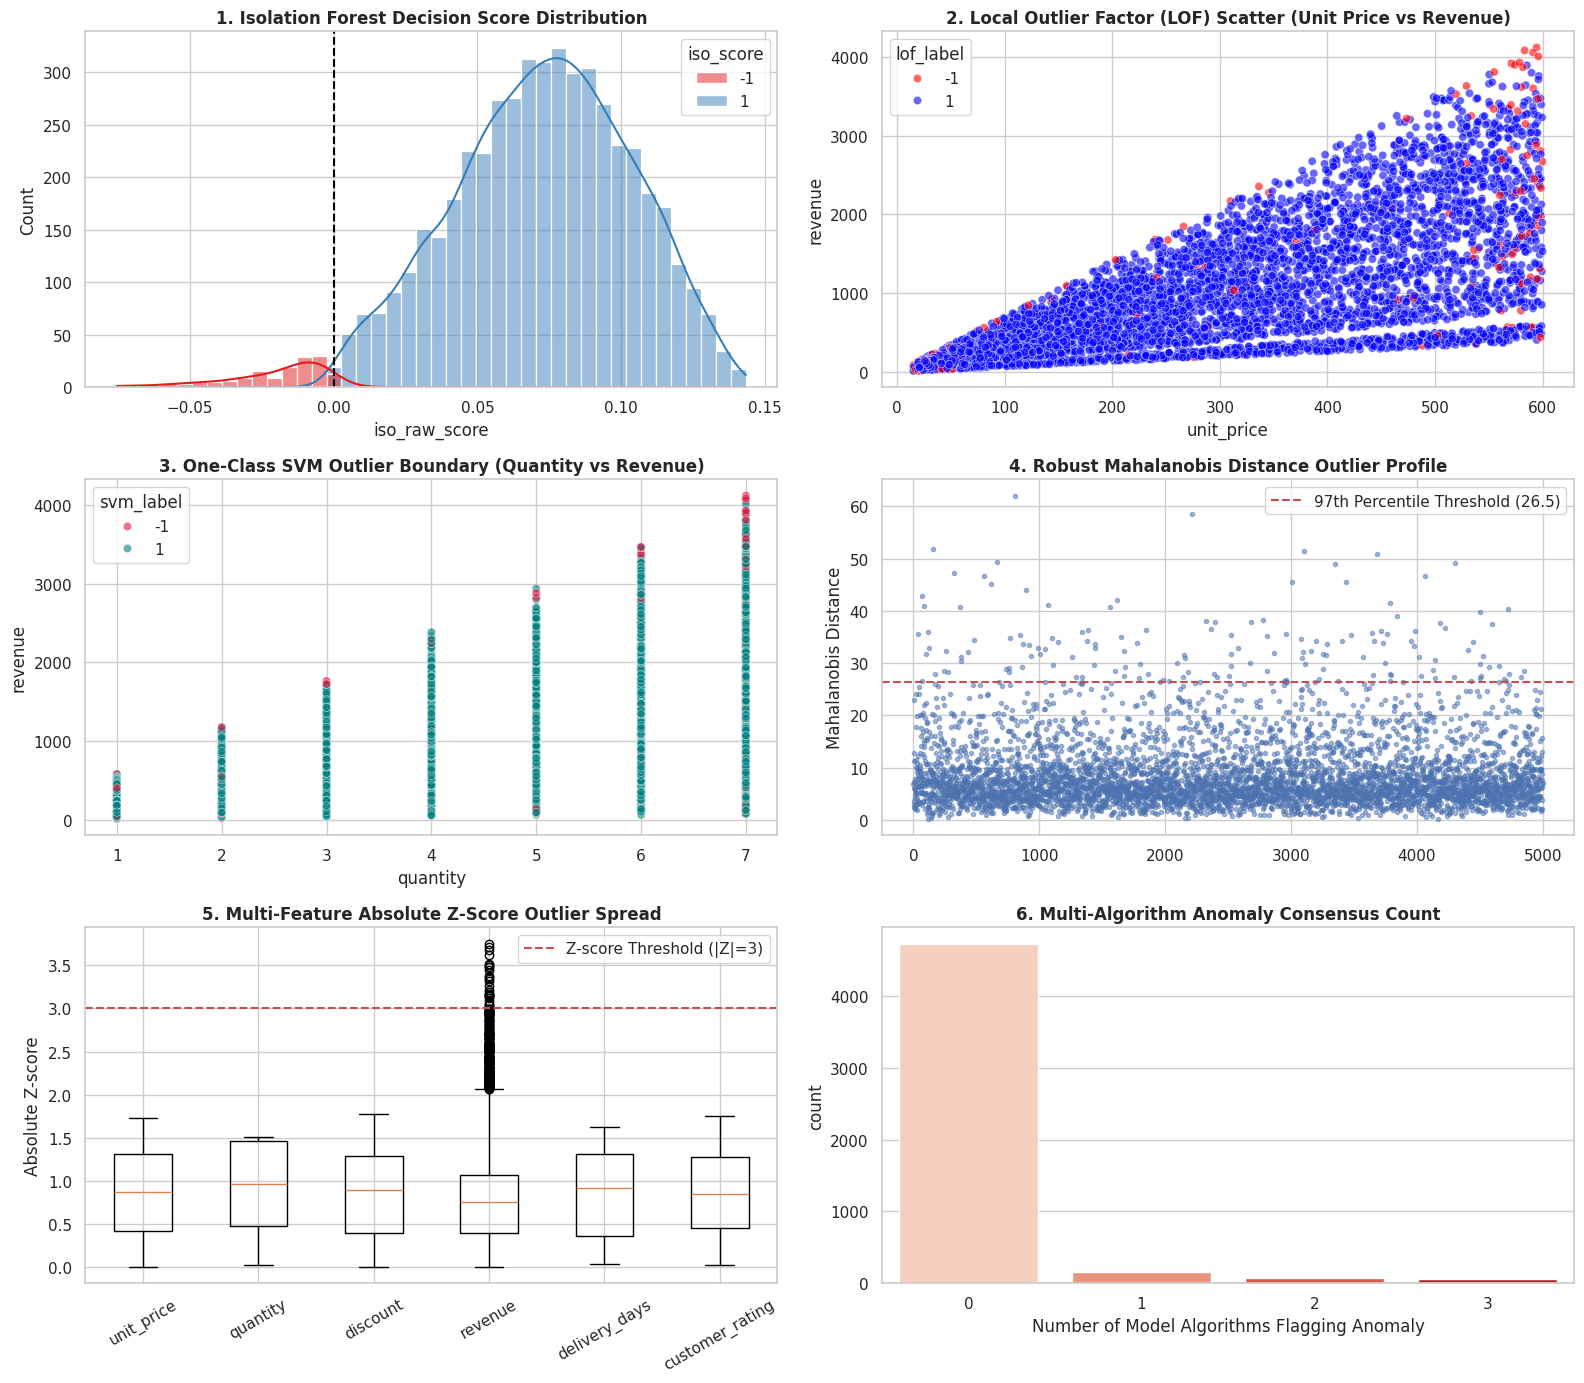

In [ ]:
# ==========================================
# ANOMALY DETECTION PLOTS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.covariance import MinCovDet

df = pd.read_csv('dataset_path')
X_num = df[['unit_price', 'quantity', 'discount', 'revenue', 'delivery_days', 'customer_rating']]
X_norm = (X_num - X_num.mean()) / X_num.std()

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

# Plot 1: Isolation Forest Anomaly Score Distribution
iso = IsolationForest(contamination=0.03, random_state=42)
df['iso_score'] = iso.fit_predict(X_norm)
df['iso_raw_score'] = iso.decision_function(X_norm)

sns.histplot(data=df, x='iso_raw_score', hue='iso_score', palette='Set1', kde=True, ax=axes[0, 0])
axes[0, 0].axvline(0, color='black', linestyle='--')
axes[0, 0].set_title('1. Isolation Forest Decision Score Distribution', fontweight='bold')

# Plot 2: Local Outlier Factor (LOF) Outlier Scatter
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
df['lof_label'] = lof.fit_predict(X_norm)
sns.scatterplot(data=df, x='unit_price', y='revenue', hue='lof_label', palette={1: 'blue', -1: 'red'}, alpha=0.6, ax=axes[0, 1])
axes[0, 1].set_title('2. Local Outlier Factor (LOF) Scatter (Unit Price vs Revenue)', fontweight='bold')

# Plot 3: One-Class SVM Outlier Frontier
oc_svm = OneClassSVM(nu=0.03, kernel='rbf', gamma='scale')
df['svm_label'] = oc_svm.fit_predict(X_norm)
sns.scatterplot(data=df, x='quantity', y='revenue', hue='svm_label', palette={1: 'teal', -1: 'crimson'}, alpha=0.6, ax=axes[1, 0])
axes[1, 0].set_title('3. One-Class SVM Outlier Boundary (Quantity vs Revenue)', fontweight='bold')

# Plot 4: Mahalanobis Distance Robust Outlier Detection
mcd = MinCovDet(random_state=42).fit(X_norm)
df['mahalanobis'] = mcd.mahalanobis(X_norm)
cutoff = np.percentile(df['mahalanobis'], 97)

axes[1, 1].plot(df.index, df['mahalanobis'], 'b.', alpha=0.5)
axes[1, 1].axhline(cutoff, color='r', linestyle='--', label=f'97th Percentile Threshold ({cutoff:.1f})')
axes[1, 1].set_title('4. Robust Mahalanobis Distance Outlier Profile', fontweight='bold')
axes[1, 1].set_ylabel('Mahalanobis Distance')
axes[1, 1].legend()

# Plot 5: Z-Score Outlier Heatmap
z_scores = np.abs(X_norm)
axes[2, 0].boxplot(z_scores.values, labels=z_scores.columns)
axes[2, 0].axhline(3.0, color='r', linestyle='--', label='Z-score Threshold (|Z|=3)')
axes[2, 0].set_title('5. Multi-Feature Absolute Z-Score Outlier Spread', fontweight='bold')
axes[2, 0].set_ylabel('Absolute Z-score')
axes[2, 0].tick_params(axis='x', rotation=30)
axes[2, 0].legend()

# Plot 6: Outlier Flag Consensus across Methods
df['total_outlier_flags'] = (df['iso_score'] == -1).astype(int) + (df['lof_label'] == -1).astype(int) + (df['svm_label'] == -1).astype(int)
sns.countplot(data=df, x='total_outlier_flags', palette='Reds', ax=axes[2, 1])
axes[2, 1].set_title('6. Multi-Algorithm Anomaly Consensus Count', fontweight='bold')
axes[2, 1].set_xlabel('Number of Model Algorithms Flagging Anomaly')

plt.tight_layout()
plt.show()

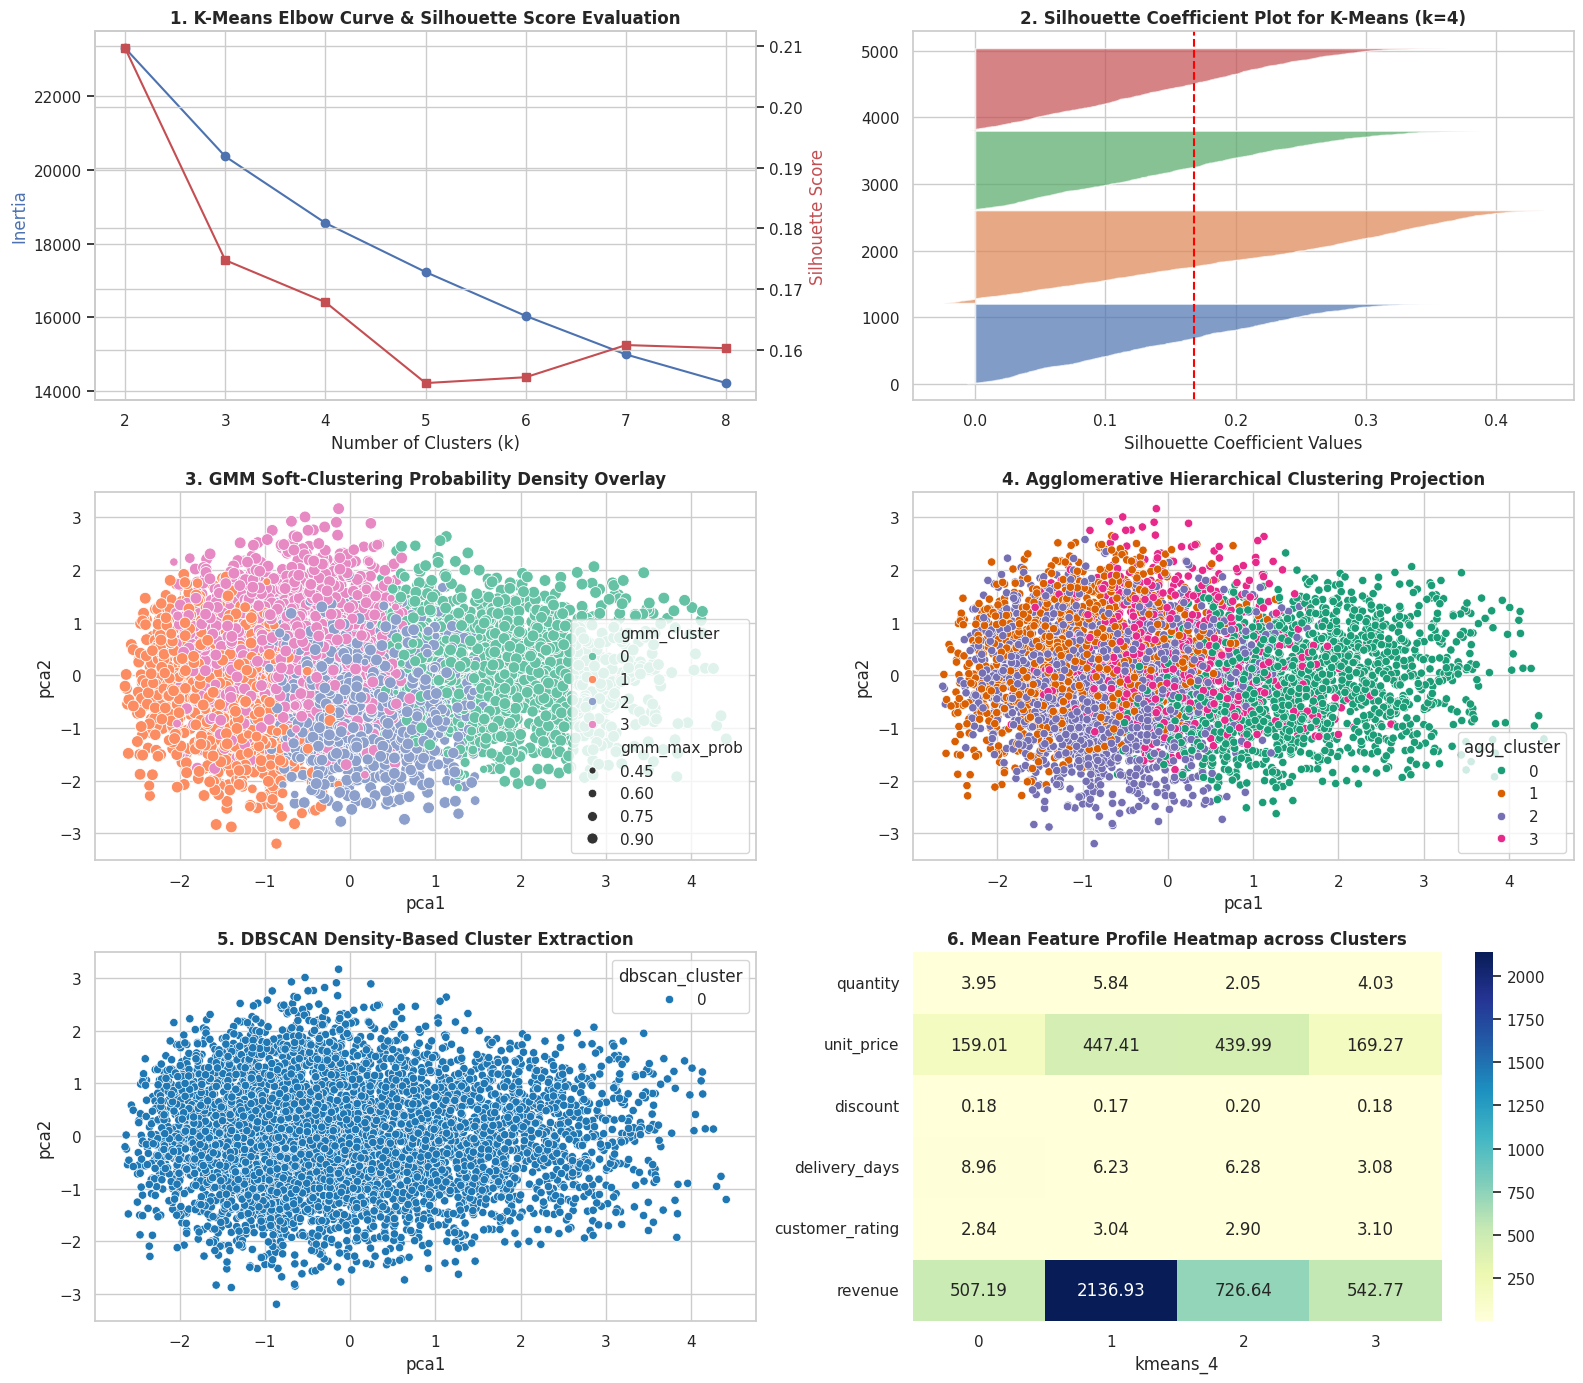

In [ ]:
# ==========================================
# CLUSTER PLOTS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

df = pd.read_csv('dataset_path')
X_num = df[['quantity', 'unit_price', 'discount', 'delivery_days', 'customer_rating', 'revenue']]
X_norm = (X_num - X_num.mean()) / X_num.std()

pca = PCA(n_components=2)
pca_coords = pca.fit_transform(X_norm)
df['pca1'] = pca_coords[:, 0]
df['pca2'] = pca_coords[:, 1]

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

# Plot 1: K-Means Inertia Elbow Curve & Silhouette Score Profile
k_range = range(2, 9)
inertias = []
silhouettes = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_norm)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_norm, km.labels_))

ax1 = axes[0, 0]
ax2 = ax1.twinx()
ax1.plot(k_range, inertias, 'b-o', label='Inertia (Elbow)')
ax2.plot(k_range, silhouettes, 'r-s', label='Silhouette Score')
ax1.set_title('1. K-Means Elbow Curve & Silhouette Score Evaluation', fontweight='bold')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia', color='b')
ax2.set_ylabel('Silhouette Score', color='r')

# Plot 2: K-Means Silhouette Analysis Plot (k=4)
km4 = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_norm)
df['kmeans_4'] = km4.labels_
sil_vals = silhouette_samples(X_norm, km4.labels_)
y_lower = 10
for i in range(4):
    ith_cluster_sil_vals = sil_vals[km4.labels_ == i]
    ith_cluster_sil_vals.sort()
    size_cluster_i = ith_cluster_sil_vals.shape[0]
    y_upper = y_lower + size_cluster_i
    axes[0, 1].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_vals, alpha=0.7)
    y_lower = y_upper + 10
axes[0, 1].axvline(x=silhouette_score(X_norm, km4.labels_), color='red', linestyle='--')
axes[0, 1].set_title('2. Silhouette Coefficient Plot for K-Means (k=4)', fontweight='bold')
axes[0, 1].set_xlabel('Silhouette Coefficient Values')

# Plot 3: Gaussian Mixture Model (GMM) Soft-Clustering Probabilities
gmm = GaussianMixture(n_components=4, random_state=42).fit(X_norm)
df['gmm_cluster'] = gmm.predict(X_norm)
df['gmm_max_prob'] = gmm.predict_proba(X_norm).max(axis=1)

sns.scatterplot(data=df, x='pca1', y='pca2', hue='gmm_cluster', size='gmm_max_prob', palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('3. GMM Soft-Clustering Probability Density Overlay', fontweight='bold')

# Plot 4: Agglomerative Hierarchical Cluster Scatter
agg = AgglomerativeClustering(n_clusters=4).fit(X_norm)
df['agg_cluster'] = agg.labels_
sns.scatterplot(data=df, x='pca1', y='pca2', hue='agg_cluster', palette='Dark2', ax=axes[1, 1])
axes[1, 1].set_title('4. Agglomerative Hierarchical Clustering Projection', fontweight='bold')

# Plot 5: DBSCAN Density-Based Cluster Projection
dbscan = DBSCAN(eps=1.2, min_samples=15).fit(X_norm)
df['dbscan_cluster'] = dbscan.labels_
sns.scatterplot(data=df, x='pca1', y='pca2', hue='dbscan_cluster', palette='tab10', ax=axes[2, 0])
axes[2, 0].set_title('5. DBSCAN Density-Based Cluster Extraction', fontweight='bold')

# Plot 6: Cluster Profiling Heatmap (Feature Means by Cluster)
cluster_profile = df.groupby('kmeans_4')[['quantity', 'unit_price', 'discount', 'delivery_days', 'customer_rating', 'revenue']].mean()
sns.heatmap(cluster_profile.T, annot=True, fmt='.2f', cmap='YlGnBu', ax=axes[2, 1])
axes[2, 1].set_title('6. Mean Feature Profile Heatmap across Clusters', fontweight='bold')

plt.tight_layout()
plt.show()

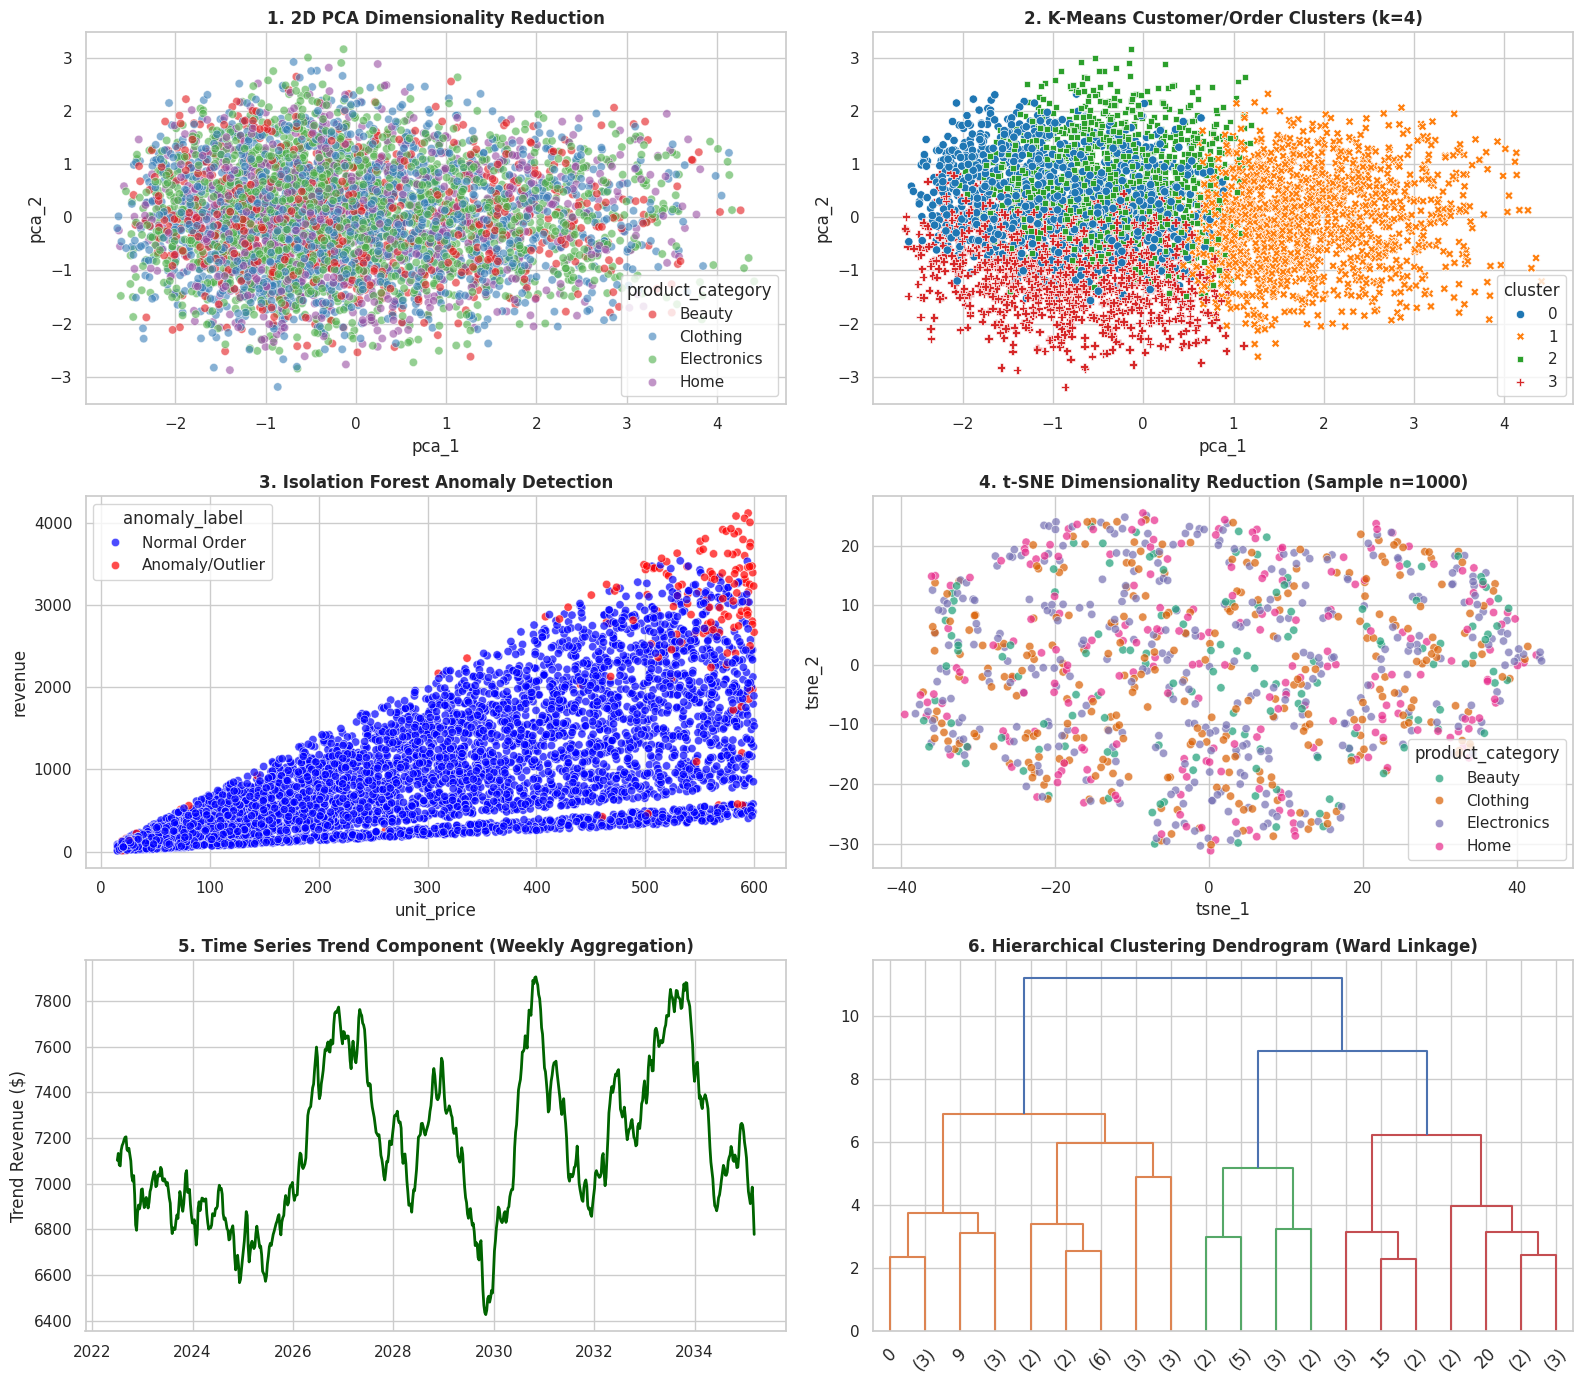

In [ ]:
# ==========================================
# ADVANCED PLOTS 
# ==========================================

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.cluster.hierarchy import dendrogram, linkage

# Pre-transform numeric data for clustering/PCA
X_num = df[['quantity', 'unit_price', 'discount', 'delivery_days', 'customer_rating', 'revenue']]
X_norm = (X_num - X_num.mean()) / X_num.std()

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

# Plot 1: Principal Component Analysis (PCA 2D Projection)
pca = PCA(n_components=2)
pca_res = pca.fit_transform(X_norm)
df['pca_1'] = pca_res[:, 0]
df['pca_2'] = pca_res[:, 1]
sns.scatterplot(data=df, x='pca_1', y='pca_2', hue='product_category', palette='Set1', alpha=0.6, ax=axes[0,0])
axes[0,0].set_title('1. 2D PCA Dimensionality Reduction', fontweight='bold')

# Plot 2: K-Means Segmentation Overlay
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_norm)
sns.scatterplot(data=df, x='pca_1', y='pca_2', hue='cluster', palette='tab10', style='cluster', ax=axes[0,1])
axes[0,1].set_title('2. K-Means Customer/Order Clusters (k=4)', fontweight='bold')

# Plot 3: Isolation Forest Anomaly Detection
iso = IsolationForest(contamination=0.03, random_state=42)
df['anomaly'] = iso.fit_predict(X_norm)
df['anomaly_label'] = df['anomaly'].map({1: 'Normal Order', -1: 'Anomaly/Outlier'})
sns.scatterplot(data=df, x='unit_price', y='revenue', hue='anomaly_label', palette={'Normal Order': 'blue', 'Anomaly/Outlier': 'red'}, alpha=0.7, ax=axes[1,0])
axes[1,0].set_title('3. Isolation Forest Anomaly Detection', fontweight='bold')

# Plot 4: t-SNE Non-Linear Manifold Projection
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_res = tsne.fit_transform(X_norm.iloc[:1000]) # Subsampled for speed
df_tsne = pd.DataFrame(tsne_res, columns=['tsne_1', 'tsne_2'])
df_tsne['product_category'] = df['product_category'].iloc[:1000].values
sns.scatterplot(data=df_tsne, x='tsne_1', y='tsne_2', hue='product_category', palette='Dark2', alpha=0.7, ax=axes[1,1])
axes[1,1].set_title('4. t-SNE Dimensionality Reduction (Sample n=1000)', fontweight='bold')

# Plot 5: Time Series Trend Decomposition Component
ts_rev = df.set_index('order_date')['revenue'].resample('W').sum()
decomp = seasonal_decompose(ts_rev, model='additive', period=52)
axes[2,0].plot(decomp.trend, color='darkgreen', linewidth=2)
axes[2,0].set_title('5. Time Series Trend Component (Weekly Aggregation)', fontweight='bold')
axes[2,0].set_ylabel('Trend Revenue ($)')

# Plot 6: Hierarchical Clustering Dendrogram
sample_norm = X_norm.sample(50, random_state=42)
linked = linkage(sample_norm, method='ward')
dendrogram(linked, ax=axes[2,1], truncate_mode='lastp', p=20, leaf_rotation=45.)
axes[2,1].set_title('6. Hierarchical Clustering Dendrogram (Ward Linkage)', fontweight='bold')

plt.tight_layout()
plt.show()